# Trabajo Práctico 2 – Aprendizaje de Máquinas
**Universidad Nacional de Colombia – Sede Medellín** · Introducción a la Inteligencia Artificial (3010476)

**Dominio:** educación. Predecimos el **nivel de desempeño en matemáticas** (Nivel 1 a 4) de los estudiantes que presentaron el **Saber 11 de 2022**, a partir de variables del estudiante, de su familia, del colegio y de sus puntajes en las demás áreas.

| Parámetro | Valor |
|---|---|
| Cédula utilizada | **1033178679** |
| Último dígito distinto de 0 | 9 → 5000 + 9 × 150 = **6350 registros** |
| Dos últimos dígitos distintos de 0 | **79** → `random_state = 79`, en la partición, los modelos, el balanceo y los outliers |
| Variable objetivo | `DESEMP_MATEMATICAS` (4 clases) |

### Estructura
**Módulo 1 – Aprendizaje supervisado**
0. Librerías, importaciones y semillas
1. Dataset: generación (opcional) y carga del subconjunto, y justificación
2. Limpieza de variables
3. Análisis exploratorio (EDA)
4. Partición y preprocesamiento: las 8 versiones de la Figura 1
5. Árboles de decisión y KNN
6. SVM y redes neuronales
7. Evaluación comparativa

**Módulo 2 – Aprendizaje no supervisado**
8. K-Means y DBSCAN sobre las 8 versiones de la Figura 2

### Resumen de decisiones
| Decisión | Justificación | Sección |
|---|---|---|
| Generación verificable desde el original | La huella SHA-256 y la comparación con el entregado demuestran que el subconjunto es reproducible | 1.1 |
| Subconjunto en el ZIP, con copia en Drive | El notebook se ejecuta sin pasos manuales, tanto en local como en Colab | 1.2 |
| Conservar los puntajes de las otras áreas | No se derivan del puntaje de matemáticas, así que no constituyen fuga | 1.3 |
| Eliminar 14 columnas | Cada eliminación está respaldada con datos: no aportan información o la duplican | 2 |
| Imputar en lugar de eliminar filas | Los nulos no son aleatorios; eliminarlos sesgaría la muestra | 3.4 |
| Correlación de Spearman | 5 de las variables analizadas son ordinales | 3.5 |
| Balancear antes de escalar | Los casos *k* y *k+4* conservan los mismos registros | 4 |
| Codificación ordinal para 5 variables y One-Hot para 13 | Se conserva el orden donde existe y no se impone donde no lo hay | 4.3 |
| StandardScaler | KNN, SVM y las redes requieren escala comparable, y se distorsiona menos que MinMax con outliers | 4.4 |
| IQR (1.5) para detectar outliers | No asume normalidad, y `EDAD` es muy asimétrica | 4.5 |
| Sin outliers: eliminar las filas | Son ~3 % del entrenamiento; recortarlas alteraría valores reales | 4.5 |
| Con outliers: reales más inyectados hasta el 5 % | Se conservan los atípicos propios del dominio y se garantiza el 5 % exacto | 4.5 |
| Desbalanceado: submuestreo a 70/10/10/10 | Solo usa registros reales; Nivel 4 determina el tamaño | 4.6 |
| Balanceado: SMOTENC | Genera registros nuevos sin crear categorías inexistentes | 4.6 |

## 0. Librerías, importaciones y semillas
La celda instala todas las dependencias para que el notebook se ejecute igual en local y en Colab:
- `imbalanced-learn`: aporta SMOTENC.
- `gdown`: solo se usa al generar el subconjunto desde el original (sección 1.1).
- Las demás librerías vienen preinstaladas en Colab.

Si alguna librería se instala por primera vez, hay que reiniciar el kernel. La semilla 79 se fija en Python, NumPy y TensorFlow, así que los resultados son reproducibles.

In [60]:
%pip install -q pandas numpy scikit-learn imbalanced-learn matplotlib seaborn tensorflow gdown


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [61]:
# ------------------------------------------------------------
# Importaciones generales
# ------------------------------------------------------------
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# ------------------------------------------------------------
# Parámetros del equipo (obligatorios según el enunciado)
# ------------------------------------------------------------
CEDULA = "1033178679"
N_REGISTROS = 5000 + 9 * 150   # último dígito distinto de cero = 9 -> 6350
SEMILLA = 79                   # dos últimos dígitos distintos de cero (no es 42)
OBJETIVO = "DESEMP_MATEMATICAS"
CLASES = ["Nivel 1", "Nivel 2", "Nivel 3", "Nivel 4"]   # orden natural de la etiqueta


def fijar_semillas(semilla=SEMILLA):
    """Fija las semillas de Python, NumPy y TensorFlow (si está instalado) para
    que todo el notebook sea reproducible."""
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla)
    np.random.seed(semilla)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(semilla)
    except ImportError:
        pass


fijar_semillas()

# ------------------------------------------------------------
# Estilo de las gráficas (paleta común para todo el notebook)
# ------------------------------------------------------------
COLOR_PRINCIPAL = "#2a78d6"                                   # serie única
COLORES_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",  # orden fijo de colores
                  "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLORES_CLASES = dict(zip(CLASES, COLORES_SERIES[:4]))
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list(
    "azul_rojo", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b8302f"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

print(f"Cédula: {CEDULA} | Registros: {N_REGISTROS} | Semilla: {SEMILLA}")

Cédula: 1033178679 | Registros: 6350 | Semilla: 79


## 1. Dataset

### 1.1 Generación del subconjunto (opcional)
El subconjunto se obtuvo del archivo completo *Resultados únicos Saber 11* (1 085 937 registros; enlace en la sección 1.3) así:
1. Se descartaron los registros sin puntaje de matemáticas válido (0–100).
2. Se construyó `DESEMP_MATEMATICAS` con los rangos oficiales del ICFES: Nivel 1 (0–35), 2 (36–50), 3 (51–70) y 4 (71–100).
3. Se eliminaron las variables con fuga de información y los identificadores (consecutivos, códigos, tipo de documento y nombres), que no describen al estudiante. Las de fuga son:
   - `PUNT_MATEMATICAS`: la etiqueta se calcula a partir de ella.
   - `PUNT_GLOBAL`: incluye el puntaje de matemáticas.
   - Los `PERCENTIL_*`.
4. Se extrajeron 6350 registros con muestreo **estratificado** por la etiqueta y `random_state = 79`. Estratificamos para conservar la proporción de niveles de la población. Con muestreo simple, la clase minoritaria (Nivel 4, 4.9 %) podría quedar sub- o sobrerrepresentada por azar.

**Ejecución desde el original.** Con `GENERAR_SUBCONJUNTO = True`, el notebook genera el subconjunto, lo usa en todas las secciones siguientes y lo compara con el entregado. Para eso:
- Obtiene el original en local o, si no está, lo descarga de Drive con `gdown` (ZIP de ~94 MB; Drive exige confirmación para archivos grandes y `gdown` la resuelve).
- Verifica su huella SHA-256. El muestreo depende del orden de las filas, así que cualquier versión distinta del archivo produciría otro subconjunto; la huella garantiza que se usa exactamente el mismo.

Por defecto la bandera está en `False`. La generación tarda alrededor de un minuto, requiere varios GB de RAM y produce un subconjunto idéntico al entregado.

In [62]:
# ============================================================
# GENERACIÓN DEL SUBCONJUNTO - SABER 11 2022
# Cédula: 1033178679 -> 6350 registros, semilla 79
# ============================================================
import hashlib
import io
import zipfile

GENERAR_SUBCONJUNTO = False   # True para generar el subconjunto desde el original y usarlo en todo el notebook

NOMBRE_ORIGINAL = "Resultados_únicos_Saber_11_20261116"
ID_DRIVE_ORIGINAL = "1gt26zB3NPERbmZ1zwE4fsRLixuNNF6gq"   # ZIP del dataset original en Google Drive
SHA256_ORIGINAL = "c6ab6629ab04a7c937cc7a8ae430c0eb36a5d042bec621901bd314524e9e7b08"   # huella del CSV original


def obtener_original(nombre=NOMBRE_ORIGINAL, id_drive=ID_DRIVE_ORIGINAL):
    """Devuelve la ruta al dataset original. Lo busca en local (.zip o .csv, en practica-2/
    o junto al notebook) y, si no está, descarga el ZIP desde Google Drive con gdown."""
    for carpeta in ("practica-2", "."):
        for extension in (".zip", ".csv"):
            ruta = os.path.join(carpeta, nombre + extension)
            if os.path.exists(ruta):
                print(f"Dataset original encontrado en local: {ruta}")
                return ruta
    import gdown
    ruta = nombre + ".zip"
    print("Descargando el dataset original (ZIP, ~94 MB) desde Google Drive...")
    gdown.download(id=id_drive, output=ruta, quiet=True)
    print(f"Descarga completa: {os.path.getsize(ruta) / 1e6:.1f} MB")
    return ruta


def sha256_original(ruta):
    """Calcula la huella SHA-256 del CSV original; si la ruta es un ZIP, la del CSV que
    contiene. Identifica la versión exacta del archivo, independiente de cómo se comprimió."""
    huella = hashlib.sha256()
    if ruta.endswith(".zip"):
        with zipfile.ZipFile(ruta) as comprimido:
            archivo = comprimido.open(comprimido.namelist()[0])
    else:
        archivo = open(ruta, "rb")
    with archivo:
        for bloque in iter(lambda: archivo.read(1 << 20), b""):
            huella.update(bloque)
    return huella.hexdigest()


def generar_subconjunto(ruta_original):
    """Genera el subconjunto de N_REGISTROS registros a partir del dataset original
    (CSV o ZIP). Retorna el DataFrame del subconjunto."""
    # 1. Cargar el dataset original (pandas lee el ZIP directamente)
    df = pd.read_csv(ruta_original, low_memory=False)
    df.columns = df.columns.str.strip().str.upper()
    print("Dataset original:", df.shape)
    print("Periodos incluidos:", df["PERIODO"].unique() if "PERIODO" in df.columns else "N/A")

    # 2. Limpiar el puntaje de matemáticas
    df["PUNT_MATEMATICAS"] = pd.to_numeric(df["PUNT_MATEMATICAS"], errors="coerce")
    df = df.dropna(subset=["PUNT_MATEMATICAS"])
    df = df[(df["PUNT_MATEMATICAS"] >= 0) & (df["PUNT_MATEMATICAS"] <= 100)]
    print("Registros con puntaje válido:", len(df))

    # 3. Variable objetivo con los rangos oficiales del ICFES
    #    Nivel 1: 0-35 | Nivel 2: 36-50 | Nivel 3: 51-70 | Nivel 4: 71-100
    df[OBJETIVO] = pd.cut(df["PUNT_MATEMATICAS"], bins=[-1, 35, 50, 70, 100],
                          labels=CLASES).astype(str)
    print("\nDistribución de clases en el dataset completo (%):")
    print((df[OBJETIVO].value_counts(normalize=True) * 100).round(2).to_string())

    # 4. Eliminar columnas con fuga de información e identificadores
    columnas_fuga = [c for c in df.columns
                     if c in ["PUNT_MATEMATICAS", "PUNT_GLOBAL"] or c.startswith("PERCENTIL")]
    columnas_id = [c for c in df.columns
                   if any(p in c for p in ["CONSECUTIVO", "COD_", "CODIGO",
                                           "TIPODOCUMENTO", "NOMBRE"])]
    columnas_eliminar = sorted(set(columnas_fuga + columnas_id))
    df = df.drop(columns=columnas_eliminar)
    print("\nColumnas eliminadas:", columnas_eliminar)

    # 5. Extraer el subconjunto de N_REGISTROS registros (estratificado)
    subconjunto, _ = train_test_split(df, train_size=N_REGISTROS,
                                      stratify=df[OBJETIVO], random_state=SEMILLA)
    subconjunto = subconjunto.reset_index(drop=True)
    print("\nSubconjunto:", subconjunto.shape)
    return subconjunto


def verificar_reproducibilidad(subconjunto, df_entregado):
    """Compara el subconjunto regenerado con el entregado. El regenerado se pasa por
    CSV (escritura y lectura) para compararlo en las mismas condiciones que el archivo
    entregado. Retorna True si son idénticos (mismas filas, columnas, orden y valores)."""
    regenerado = pd.read_csv(io.StringIO(subconjunto.to_csv(index=False)))
    return regenerado.equals(df_entregado)


subconjunto_regenerado = None
if GENERAR_SUBCONJUNTO:
    ruta_original = obtener_original()
    huella = sha256_original(ruta_original)
    print(f"SHA-256 del CSV original: {huella}")
    print(f"¿Es la misma versión del dataset que usó el equipo? {huella == SHA256_ORIGINAL}\n")
    subconjunto_regenerado = generar_subconjunto(ruta_original)
else:
    print("Generación omitida (GENERAR_SUBCONJUNTO = False): en la sección 1.2 se carga "
          "el subconjunto ya generado.")

Generación omitida (GENERAR_SUBCONJUNTO = False): en la sección 1.2 se carga el subconjunto ya generado.


### 1.2 Carga del subconjunto
Si el subconjunto se generó en la sección 1.1, se usa ese. Si no, se carga el subconjunto entregado (1.7 MB), primero desde local (junto al notebook o en `practica-2/`) y, si no está, desde Google Drive.

Incluimos el CSV en el ZIP y además una copia en Drive para que la ejecución no dependa de subir archivos manualmente:
- En Colab normalmente solo se abre el `.ipynb`, así que sin la copia en Drive la carga fallaría.
- La búsqueda local evita depender de internet.

Si Drive devuelve una página en lugar del CSV, el notebook muestra un mensaje con la causa y la solución.

In [63]:
NOMBRE_CSV = "saber11_2022_subconjunto_6350.csv"
# Junto al notebook o en practica-2/ (si se corre desde la raíz del repo)
RUTAS_LOCALES = [NOMBRE_CSV, os.path.join("practica-2", NOMBRE_CSV)]
ID_DRIVE = "1OlXeSYGOxs5oxV0I4HFMOskja72iIaH-"   # ID del CSV del subconjunto en Google Drive
URL_DRIVE = f"https://drive.google.com/uc?export=download&id={ID_DRIVE}"


def descargar_csv_drive(url):
    """Descarga un CSV público de Google Drive. Si Drive responde con una página HTML
    (archivo no compartido públicamente), lanza un error con instrucciones claras."""
    import io
    import urllib.request
    with urllib.request.urlopen(url) as respuesta:
        contenido = respuesta.read()
    if contenido.lstrip()[:1] == b"<":
        raise RuntimeError(
            "Google Drive devolvió una página web en lugar del CSV. Verifique que el archivo "
            "esté compartido como 'Cualquier persona con el enlace', o suba "
            f"'{NOMBRE_CSV}' (incluido en el ZIP) al panel de archivos de Colab y vuelva "
            "a ejecutar esta celda.")
    return pd.read_csv(io.BytesIO(contenido))


def cargar_subconjunto(rutas_locales=RUTAS_LOCALES, url_drive=URL_DRIVE):
    """Carga el subconjunto. Primero lo busca en las rutas locales y, si no lo
    encuentra, lo descarga desde Google Drive."""
    for ruta in rutas_locales:
        if os.path.exists(ruta):
            df = pd.read_csv(ruta)
            origen = f"local ({ruta})"
            break
    else:
        print("No se encontró el CSV en local; se descarga desde Google Drive.")
        df = descargar_csv_drive(url_drive)
        origen = "Google Drive"
    print(f"Subconjunto cargado desde {origen}: {df.shape[0]} filas x {df.shape[1]} columnas")
    return df


if GENERAR_SUBCONJUNTO:
    # Se usa el subconjunto generado en la 1.1. Se pasa por CSV (escribir y leer) para que
    # quede exactamente igual que al leer el archivo entregado (mismos tipos de datos).
    df_raw = pd.read_csv(io.StringIO(subconjunto_regenerado.to_csv(index=False)))
    print(f"Se usa el subconjunto generado en la sección 1.1: "
          f"{df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
    try:
        df_entregado = cargar_subconjunto()
        print("¿El subconjunto generado es idéntico al entregado?",
              verificar_reproducibilidad(subconjunto_regenerado, df_entregado))
    except Exception as error:
        print(f"No se pudo cargar el subconjunto entregado para compararlo ({error}).")
else:
    df_raw = cargar_subconjunto()

df_raw.head()

Subconjunto cargado desde local (saber11_2022_subconjunto_6350.csv): 6350 filas x 37 columnas


,PERIODO,COLE_AREA_UBICACION,COLE_BILINGUE,COLE_CALENDARIO,COLE_CARACTER,COLE_DEPTO_UBICACION,COLE_GENERO,COLE_JORNADA,COLE_MCPIO_UBICACION,COLE_NATURALEZA,COLE_SEDE_PRINCIPAL,ESTU_DEPTO_PRESENTACION,ESTU_DEPTO_RESIDE,ESTU_ESTADOINVESTIGACION,ESTU_ESTUDIANTE,ESTU_FECHANACIMIENTO,ESTU_GENERO,ESTU_MCPIO_PRESENTACION,ESTU_MCPIO_RESIDE,ESTU_NACIONALIDAD,ESTU_PAIS_RESIDE,ESTU_PRIVADO_LIBERTAD,FAMI_CUARTOSHOGAR,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA,FAMI_PERSONASHOGAR,FAMI_TIENEAUTOMOVIL,FAMI_TIENECOMPUTADOR,FAMI_TIENEINTERNET,FAMI_TIENELAVADORA,DESEMP_INGLES,PUNT_INGLES,PUNT_SOCIALES_CIUDADANAS,PUNT_C_NATURALES,PUNT_LECTURA_CRITICA,DESEMP_MATEMATICAS
0,20224,RURAL,N,A,ACADÉMICO,LA GUAJIRA,MIXTO,UNICA,MANAURE,OFICIAL,S,LA GUAJIRA,LA GUAJIRA,PUBLICAR,ESTUDIANTE,16/12/2004,F,RIOHACHA,MANAURE,COLOMBIA,COLOMBIA,N,Tres,Primaria incompleta,Ninguno,Estrato 1,3 a 4,No,Si,No,Si,A-,0.0,42,39,50,Nivel 3
1,20224,RURAL,N,A,TÉCNICO/ACADÉMICO,HUILA,MIXTO,COMPLETA,LA PLATA,OFICIAL,S,HUILA,HUILA,PUBLICAR,ESTUDIANTE,27/03/2006,F,LA PLATA,LA PLATA,COLOMBIA,COLOMBIA,N,Dos,Primaria incompleta,Primaria incompleta,Estrato 1,5 a 6,No,No,No,No,A1,54.0,32,35,53,Nivel 1
2,20224,URBANO,NaN,A,NaN,ATLANTICO,MIXTO,UNICA,BARRANQUILLA,OFICIAL,S,ATLANTICO,ATLANTICO,PUBLICAR,ESTUDIANTE,24/03/2006,M,BARRANQUILLA,BARRANQUILLA,COLOMBIA,COLOMBIA,N,Dos,Secundaria (Bachillerato) completa,Primaria incompleta,Estrato 1,3 a 4,No,No,Si,Si,B1,73.0,62,53,70,Nivel 3
3,20221,URBANO,N,B,TÉCNICO,VALLE,MIXTO,COMPLETA,GUADALAJARA DE BUGA,NO OFICIAL,S,VALLE,VALLE,PUBLICAR,ESTUDIANTE,30/05/2005,M,GUADALAJARA DE BUGA,GUADALAJARA DE BUGA,COLOMBIA,COLOMBIA,N,Cuatro,Educación profesional incompleta,No Aplica,Estrato 2,5 a 6,No,Si,Si,Si,B1,72.0,74,66,69,Nivel 3
4,20224,URBANO,NaN,A,NaN,BOLIVAR,MIXTO,UNICA,CARTAGENA DE INDIAS,OFICIAL,S,BOLIVAR,BOLIVAR,PUBLICAR,ESTUDIANTE,19/08/2004,F,CARTAGENA DE INDIAS,CARTAGENA DE INDIAS,COLOMBIA,COLOMBIA,N,Dos,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Estrato 5,3 a 4,No,No,No,No,A-,37.0,40,38,52,Nivel 2


### 1.3 Justificación del dataset
- **Fuente:** resultados del Saber 11 de 2022, publicados por el ICFES como datos abiertos. Archivo *Resultados únicos Saber 11* (ZIP), con 1 085 937 registros y 51 columnas de las aplicaciones 2022-1 y 2022-2. Enlace al dataset original: <https://drive.google.com/file/d/1gt26zB3NPERbmZ1zwE4fsRLixuNNF6gq/view?usp=sharing>
- **Pertinencia:** el desempeño en matemáticas es determinante en el acceso a la educación superior. Predecirlo a partir del contexto del estudiante permite identificar a tiempo a quienes tienen riesgo de quedar en los niveles bajos.
- **Requisitos del enunciado:** 6350 registros (≥ 5000), 4 clases y variables numéricas y categóricas. La celda siguiente lo verifica.
- **Variables:** el subconjunto tiene 37 columnas (36 variables y el objetivo). Después de la limpieza (sección 2) quedan **23 predictores**: 5 numéricos, 5 ordinales y 13 nominales.

| # | Variable | Descripción | Tipo | ¿Se usa? |
|---|---|---|---|---|
| 1 | `PUNT_LECTURA_CRITICA` | Puntaje en lectura crítica (0–100) | Numérica | ✅ |
| 2 | `PUNT_C_NATURALES` | Puntaje en ciencias naturales (0–100) | Numérica | ✅ |
| 3 | `PUNT_SOCIALES_CIUDADANAS` | Puntaje en sociales y ciudadanas (0–100) | Numérica | ✅ |
| 4 | `PUNT_INGLES` | Puntaje en inglés (0–100) | Numérica | ✅ |
| 5 | `ESTU_FECHANACIMIENTO` | Fecha de nacimiento | Fecha | ✅ Se transforma en `EDAD` (numérica) |
| 6 | `FAMI_ESTRATOVIVIENDA` | Estrato de la vivienda (Sin estrato, 1–6) | Ordinal | ✅ |
| 7 | `FAMI_EDUCACIONMADRE` | Máximo nivel educativo de la madre | Ordinal | ✅ |
| 8 | `FAMI_EDUCACIONPADRE` | Máximo nivel educativo del padre | Ordinal | ✅ |
| 9 | `FAMI_CUARTOSHOGAR` | Número de cuartos del hogar | Ordinal | ✅ |
| 10 | `FAMI_PERSONASHOGAR` | Número de personas del hogar | Ordinal | ✅ |
| 11 | `COLE_AREA_UBICACION` | Colegio urbano o rural | Nominal | ✅ |
| 12 | `COLE_BILINGUE` | Colegio bilingüe (S/N) | Nominal | ✅ |
| 13 | `COLE_CARACTER` | Académico, técnico o técnico/académico | Nominal | ✅ |
| 14 | `COLE_DEPTO_UBICACION` | Departamento del colegio (33) | Nominal | ✅ |
| 15 | `COLE_GENERO` | Colegio mixto, femenino o masculino | Nominal | ✅ |
| 16 | `COLE_JORNADA` | Mañana, tarde, única, completa, noche o sabatina | Nominal | ✅ |
| 17 | `COLE_NATURALEZA` | Oficial o no oficial | Nominal | ✅ |
| 18 | `COLE_SEDE_PRINCIPAL` | Si es la sede principal (S/N) | Nominal | ✅ |
| 19 | `ESTU_GENERO` | Género del estudiante (F/M) | Nominal | ✅ |
| 20 | `FAMI_TIENEAUTOMOVIL` | El hogar tiene automóvil (Sí/No) | Nominal | ✅ |
| 21 | `FAMI_TIENECOMPUTADOR` | El hogar tiene computador (Sí/No) | Nominal | ✅ |
| 22 | `FAMI_TIENEINTERNET` | El hogar tiene internet (Sí/No) | Nominal | ✅ |
| 23 | `FAMI_TIENELAVADORA` | El hogar tiene lavadora (Sí/No) | Nominal | ✅ |
| 24 | `COLE_MCPIO_UBICACION` | Municipio del colegio | Nominal | ❌ ~770 categorías; se usa el departamento |
| 25 | `ESTU_MCPIO_RESIDE` | Municipio de residencia | Nominal | ❌ ~770 categorías |
| 26 | `ESTU_MCPIO_PRESENTACION` | Municipio donde presentó la prueba | Nominal | ❌ ~450 categorías |
| 27 | `ESTU_DEPTO_RESIDE` | Departamento de residencia | Nominal | ❌ Igual al del colegio en ~99 % |
| 28 | `ESTU_DEPTO_PRESENTACION` | Departamento donde presentó la prueba | Nominal | ❌ Igual al del colegio en ~98 % |
| 29 | `ESTU_PAIS_RESIDE` | País de residencia | Nominal | ❌ Duplica la nacionalidad |
| 30 | `ESTU_NACIONALIDAD` | Nacionalidad | Nominal | ❌ 98.7 % colombianos (casi constante) |
| 31 | `COLE_CALENDARIO` | Calendario A, B u otro | Nominal | ❌ 98.3 % calendario A (casi constante) |
| 32 | `ESTU_PRIVADO_LIBERTAD` | Privado de la libertad (S/N) | Nominal | ❌ 99.9 % "N" (casi constante) |
| 33 | `ESTU_ESTADOINVESTIGACION` | Estado del resultado | Nominal | ❌ Constante |
| 34 | `ESTU_ESTUDIANTE` | Tipo de evaluado | Nominal | ❌ Constante |
| 35 | `PERIODO` | Periodo de aplicación (2022-1 o 2022-2) | Administrativa | ❌ No describe al estudiante |
| 36 | `DESEMP_INGLES` | Nivel de inglés (A−, A1, …, B+) | Ordinal | ❌ Es `PUNT_INGLES` en rangos (redundante) |
| — | **`DESEMP_MATEMATICAS`** | **Nivel de desempeño en matemáticas (1–4)** | **Objetivo** | 🎯 4 clases |

- **Puntajes de las otras áreas:** los conservamos como predictores porque no se derivan del puntaje de matemáticas. Son pruebas independientes del mismo examen. Las variables con fuga (`PUNT_MATEMATICAS` y `PUNT_GLOBAL`) se eliminaron en la generación. Además, son prácticamente las únicas variables numéricas disponibles para el tratamiento de outliers.

In [64]:
def verificar_requisitos(df, objetivo=OBJETIVO, n_esperado=N_REGISTROS):
    """Verifica los requisitos del enunciado: al menos 5000 registros (exactamente
    N_REGISTROS), al menos 4 clases y presencia de variables numéricas y categóricas."""
    numericas = df.drop(columns=objetivo).select_dtypes(include="number").columns
    categoricas = df.drop(columns=objetivo).select_dtypes(exclude="number").columns
    requisitos = pd.DataFrame({
        "Requisito": ["Registros >= 5000", f"Registros = {n_esperado} (cédula)",
                      "Clases del objetivo >= 4", "Tiene variables numéricas",
                      "Tiene variables categóricas"],
        "Valor": [len(df), len(df), df[objetivo].nunique(), len(numericas), len(categoricas)],
        "Cumple": [len(df) >= 5000, len(df) == n_esperado, df[objetivo].nunique() >= 4,
                   len(numericas) > 0, len(categoricas) > 0],
    })
    assert requisitos["Cumple"].all(), "El dataset no cumple algún requisito del enunciado"
    return requisitos


verificar_requisitos(df_raw)

,Requisito,Valor,Cumple
0,Registros >= 5000,6350,True
1,Registros = 6350 (cédula),6350,True
2,Clases del objetivo >= 4,4,True
3,Tiene variables numéricas,5,True
4,Tiene variables categóricas,31,True


## 2. Limpieza de variables
La fuga directa y los identificadores se eliminaron al generar el subconjunto (sección 1.1). En esta sección eliminamos 14 columnas más, y cada eliminación está respaldada por la evidencia de la celda siguiente:
- **a)** resumen general
- **b)** constantes y casi constantes
- **c)** `PERIODO`
- **d)** fecha de nacimiento
- **e)** municipios
- **f)** columnas duplicadas
- **g)** `DESEMP_INGLES`

Estos porcentajes se calculan sobre todo el subconjunto porque son descriptivos. La decisión sobre qué columnas son casi constantes, en cambio, se toma solo con el entrenamiento.

In [65]:
# ============================================================
# EVIDENCIA CON DATOS DE LAS COLUMNAS QUE SE ELIMINAN
# ============================================================
COLUMNAS_CANDIDATAS = [
    "ESTU_ESTADOINVESTIGACION", "ESTU_ESTUDIANTE", "COLE_CALENDARIO", "ESTU_NACIONALIDAD",
    "ESTU_PRIVADO_LIBERTAD", "PERIODO", "ESTU_FECHANACIMIENTO", "COLE_MCPIO_UBICACION",
    "ESTU_MCPIO_RESIDE", "ESTU_MCPIO_PRESENTACION", "ESTU_DEPTO_RESIDE",
    "ESTU_DEPTO_PRESENTACION", "ESTU_PAIS_RESIDE", "DESEMP_INGLES",
]


def resumen_columnas(df, columnas):
    """Para cada columna: valores distintos, valor más frecuente, % de filas con ese valor y nulos."""
    filas = []
    for col in columnas:
        conteo = df[col].value_counts(dropna=False)
        filas.append({"Columna": col, "Valores distintos": df[col].nunique(),
                      "Valor más frecuente": conteo.index[0],
                      "% del más frecuente": round(conteo.iloc[0] / len(df) * 100, 2),
                      "Nulos": int(df[col].isna().sum())})
    return pd.DataFrame(filas).set_index("Columna")


def dispersion_categorias(df, columnas, minimo=5):
    """Para cada columna: número de categorías, cuántas tienen menos de `minimo`
    registros y cuántas aparecen una sola vez."""
    filas = []
    for col in columnas:
        conteo = df[col].value_counts()
        filas.append({"Columna": col, "Categorías": len(conteo),
                      f"Con < {minimo} registros": int((conteo < minimo).sum()),
                      f"% con < {minimo} registros": round((conteo < minimo).mean() * 100, 1),
                      "Con 1 solo registro": int((conteo == 1).sum())})
    return pd.DataFrame(filas).set_index("Columna")


def coincidencia(df, col_a, col_b):
    """Porcentaje de filas en que dos columnas categóricas tienen el mismo valor."""
    return round((df[col_a] == df[col_b]).mean() * 100, 2)


# a) Tabla general de las 14 columnas
print("a) RESUMEN DE LAS 14 COLUMNAS CANDIDATAS A ELIMINAR")
display(resumen_columnas(df_raw, COLUMNAS_CANDIDATAS))

# b) Constantes y casi constantes (umbral: un valor ocupa > 98 % de las filas)
print("\nb) CONSTANTES Y CASI CONSTANTES (% de filas por valor)")
for col in ["ESTU_ESTADOINVESTIGACION", "ESTU_ESTUDIANTE", "COLE_CALENDARIO",
            "ESTU_NACIONALIDAD", "ESTU_PRIVADO_LIBERTAD"]:
    porcentajes = (df_raw[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    print(f"  {col}: {porcentajes.to_dict()}")

# c) PERIODO: distribución, relación con el calendario y con el objetivo
print("\nc) PERIODO")
print("  Distribución:", df_raw["PERIODO"].value_counts().to_dict())
print("  PERIODO vs. COLE_CALENDARIO (registros):")
display(pd.crosstab(df_raw["PERIODO"], df_raw["COLE_CALENDARIO"], margins=True, margins_name="Total"))
print("  Distribución del objetivo por PERIODO (% por fila):")
display((pd.crosstab(df_raw["PERIODO"], df_raw[OBJETIVO], normalize="index") * 100).round(1))

# d) Fecha de nacimiento
print("d) ESTU_FECHANACIMIENTO")
fechas = pd.to_datetime(df_raw["ESTU_FECHANACIMIENTO"], format="%d/%m/%Y", errors="coerce")
print(f"  Tipo: {df_raw['ESTU_FECHANACIMIENTO'].dtype} (texto) | "
      f"valores distintos: {df_raw['ESTU_FECHANACIMIENTO'].nunique()}")
print(f"  Rango: {fechas.min().date()} a {fechas.max().date()} | nulos: {fechas.isna().sum()} | "
      f"nacidos después de 2009 (imposible para un bachiller): {int((fechas.dt.year > 2009).sum())}")

# e) Municipios: cardinalidad y dispersión (el departamento como referencia)
print("\ne) MUNICIPIOS: CATEGORÍAS CON POCOS REGISTROS")
display(dispersion_categorias(df_raw, ["COLE_MCPIO_UBICACION", "ESTU_MCPIO_RESIDE",
                                       "ESTU_MCPIO_PRESENTACION", "COLE_DEPTO_UBICACION"]))

# f) Columnas duplicadas: coincidencia fila a fila
print("f) COLUMNAS DUPLICADAS (% de filas con el mismo valor)")
for col_a, col_b in [("ESTU_PAIS_RESIDE", "ESTU_NACIONALIDAD"),
                     ("ESTU_DEPTO_RESIDE", "COLE_DEPTO_UBICACION"),
                     ("ESTU_DEPTO_PRESENTACION", "COLE_DEPTO_UBICACION")]:
    print(f"  {col_a:<25} vs {col_b:<22}: {coincidencia(df_raw, col_a, col_b)} %")
print("  ESTU_NACIONALIDAD vs ESTU_PAIS_RESIDE (todos los valores en la diagonal):")
display(pd.crosstab(df_raw["ESTU_NACIONALIDAD"], df_raw["ESTU_PAIS_RESIDE"]))

# g) DESEMP_INGLES es una discretización de PUNT_INGLES
print("g) DESEMP_INGLES vs PUNT_INGLES: rangos de puntaje por nivel (no se traslapan)")
display(df_raw.groupby("DESEMP_INGLES")["PUNT_INGLES"].agg(["min", "max", "count"]).sort_values("min"))
orden_ingles = {"A-": 0, "A1": 1, "A2": 2, "B1": 3, "B+": 4}
rho = df_raw["PUNT_INGLES"].corr(df_raw["DESEMP_INGLES"].map(orden_ingles), method="spearman")
print(f"  Correlación de Spearman entre PUNT_INGLES y DESEMP_INGLES: {rho:.3f}")

a) RESUMEN DE LAS 14 COLUMNAS CANDIDATAS A ELIMINAR


,Valores distintos,Valor más frecuente,% del más frecuente,Nulos
Columna,,,,
ESTU_ESTADOINVESTIGACION,1,PUBLICAR,100.00,0
ESTU_ESTUDIANTE,1,ESTUDIANTE,100.00,0
COLE_CALENDARIO,3,A,98.30,0
ESTU_NACIONALIDAD,6,COLOMBIA,98.72,0
ESTU_PRIVADO_LIBERTAD,2,N,99.91,0
PERIODO,2,20224,98.33,0
ESTU_FECHANACIMIENTO,1699,12/10/2005,0.28,3
COLE_MCPIO_UBICACION,771,BOGOTÁ D.C.,15.24,0
ESTU_MCPIO_RESIDE,774,BOGOTÁ D.C.,15.34,0



b) CONSTANTES Y CASI CONSTANTES (% de filas por valor)
  ESTU_ESTADOINVESTIGACION: {'PUBLICAR': 100.0}
  ESTU_ESTUDIANTE: {'ESTUDIANTE': 100.0}
  COLE_CALENDARIO: {'A': 98.3, 'B': 1.28, 'OTRO': 0.43}
  ESTU_NACIONALIDAD: {'COLOMBIA': 98.72, 'VENEZUELA': 1.21, 'ECUADOR': 0.02, 'BRASIL': 0.02, 'PANAMÁ': 0.02, 'CHILE': 0.02}
  ESTU_PRIVADO_LIBERTAD: {'N': 99.91, 'S': 0.09}

c) PERIODO
  Distribución: {20224: 6244, 20221: 106}
  PERIODO vs. COLE_CALENDARIO (registros):


COLE_CALENDARIO,A,B,OTRO,Total
PERIODO,,,,
20221,28,74,4,106
20224,6214,7,23,6244
Total,6242,81,27,6350


  Distribución del objetivo por PERIODO (% por fila):


DESEMP_MATEMATICAS,Nivel 1,Nivel 2,Nivel 3,Nivel 4
PERIODO,,,,
20221,3.8,22.6,51.9,21.7
20224,12.0,36.8,46.6,4.6


... (3 outputs left out)

ESTU_PAIS_RESIDE,BRASIL,CHILE,COLOMBIA,ECUADOR,PANAMÁ,VENEZUELA
ESTU_NACIONALIDAD,,,,,,
BRASIL,1,0,0,0,0,0
CHILE,0,1,0,0,0,0
COLOMBIA,0,0,6269,0,0,0
ECUADOR,0,0,0,1,0,0
PANAMÁ,0,0,0,0,1,0
VENEZUELA,0,0,0,0,0,77


g) DESEMP_INGLES vs PUNT_INGLES: rangos de puntaje por nivel (no se traslapan)


,min,max,count
DESEMP_INGLES,,,
A-,0.0,47.0,2922
A1,48.0,57.0,1658
A2,58.0,67.0,1015
B1,68.0,78.0,567
B+,79.0,100.0,158


  Correlación de Spearman entre PUNT_INGLES y DESEMP_INGLES: 0.937


#### Justificación de cada eliminación
- **b) Constantes y casi constantes.** Fijamos el umbral en **98 %** del valor más frecuente.
  - Por encima del umbral, los demás valores suman menos de ~90 registros de entrenamiento, que no son suficientes para aprender un patrón confiable.
  - `COLE_GENERO` (97.4 % mixto) queda por debajo y la conservamos: los colegios femeninos y masculinos tienen 12–14 % de Nivel 4, frente a 4.7 % en los mixtos.
- **c) `PERIODO`.** Tiene relación con el objetivo (21.7 % de Nivel 4 en `20221` frente a 4.6 % en `20224`), pero la eliminamos por tres razones:
  - **La relación viene del calendario B, que ya está representado en otras variables.** El periodo `20221` corresponde casi en su totalidad a colegios de calendario B. En los datos, el calendario B es 100 % no oficial, 29.6 % bilingüe y 55.6 % de estrato 4 o superior (en calendario A: 23.8 %, 1 % y 8 %). Esa información ya la capturan `COLE_NATURALEZA`, `COLE_BILINGUE` y `FAMI_ESTRATOVIVIENDA`.
  - **Es una variable administrativa:** indica *cuándo* se presentó el examen, no características del estudiante.
  - **Es casi constante:** solo hay 71 registros de `20221` en entrenamiento.
- **d) Fecha de nacimiento.** Tiene ~1700 valores distintos como texto. La reemplazamos por `EDAD`, que es la información relevante: la extraedad se asocia a un menor desempeño (sección 3.6).
- **e) Municipios.** El One-Hot agregaría ~2000 columnas, y el ~70 % de los municipios tiene menos de 5 registros. El departamento (33 categorías) conserva la información regional con un número suficiente de registros por categoría.
- **f) y g) Duplicadas y redundantes.** Su información ya está en columnas que conservamos.

| Columna | Evidencia | Decisión |
|---|---|---|
| `ESTU_ESTADOINVESTIGACION`, `ESTU_ESTUDIANTE` | Un solo valor en el 100 % de las filas | Eliminar (constantes) |
| `COLE_CALENDARIO`, `ESTU_NACIONALIDAD`, `ESTU_PRIVADO_LIBERTAD` | Un valor ocupa el 98.3 %, el 98.7 % y el 99.9 % de las filas | Eliminar (casi constantes) |
| `PERIODO` | El 98.3 % es `20224`; refleja el calendario del colegio | Eliminar (administrativa) |
| `ESTU_FECHANACIMIENTO` | Texto con ~1700 valores distintos | Reemplazar por `EDAD` |
| `COLE_MCPIO_UBICACION`, `ESTU_MCPIO_RESIDE`, `ESTU_MCPIO_PRESENTACION` | 453–774 categorías; ~46–70 % de ellas con menos de 5 registros | Eliminar (se usa el departamento) |
| `ESTU_DEPTO_RESIDE`, `ESTU_DEPTO_PRESENTACION` | Coinciden con `COLE_DEPTO_UBICACION` en el 98.9 % y el 97.9 % de las filas | Eliminar (redundantes) |
| `ESTU_PAIS_RESIDE` | Coincide con `ESTU_NACIONALIDAD` en el 100 % de las filas | Eliminar (duplicada) |
| `DESEMP_INGLES` | Rangos de `PUNT_INGLES` sin traslape; ρ de Spearman ≈ 0.94 | Eliminar (redundante) |

#### Limpieza
La celda siguiente aplica estas eliminaciones y, además:
- **Calcula `EDAD`** a la fecha de referencia del 1 de septiembre de 2022. Corresponde aproximadamente a la aplicación 2022-2, en la que está el 98.3 % de los registros, y un desfase de pocas semanas no altera la edad en años.
- **Pasa a nulo las edades fuera del rango 13–80**, porque corresponden a fechas imposibles (nacimientos en 2013 y 2022). El límite superior es amplio porque los datos contienen adultos reales de hasta 67 años (validación de bachillerato y jornadas nocturna y sabatina).
- **Pasa a nulo "No sabe" y "No Aplica"** en la educación de los padres: no tienen posición en la escala de *Ninguno* a *Postgrado*, así que los tratamos como faltantes y se imputan.
- **Detecta las casi constantes solo con el entrenamiento**, ya que es una decisión aprendida de los datos. Usamos la misma partición de la sección 4.1 y verificamos que el resultado coincide con el de todo el subconjunto.

In [66]:
# ------------------------------------------------------------
# Columnas que se eliminan explícitamente y su justificación
# ------------------------------------------------------------
COLUMNAS_A_ELIMINAR = {
    "ESTU_ESTADOINVESTIGACION": "Constante (todos 'PUBLICAR'): no aporta información",
    "ESTU_ESTUDIANTE":          "Constante (todos 'ESTUDIANTE'): no aporta información",
    "PERIODO":                  "Administrativa (periodo de aplicación); no describe al estudiante",
    "ESTU_FECHANACIMIENTO":     "Se reemplaza por la variable numérica EDAD",
    "COLE_MCPIO_UBICACION":     "Alta cardinalidad (~770 municipios): One-Hot inviable; se usa el departamento",
    "ESTU_MCPIO_RESIDE":        "Alta cardinalidad; redundante con la ubicación del colegio",
    "ESTU_MCPIO_PRESENTACION":  "Alta cardinalidad; lugar logístico de la prueba",
    "ESTU_DEPTO_RESIDE":        "Redundante con COLE_DEPTO_UBICACION (coinciden en ~99 % de los casos)",
    "ESTU_DEPTO_PRESENTACION":  "Redundante con COLE_DEPTO_UBICACION; lugar logístico de la prueba",
    "ESTU_PAIS_RESIDE":         "Duplica ESTU_NACIONALIDAD",
    "DESEMP_INGLES":            "Discretización de PUNT_INGLES: información redundante",
}
UMBRAL_CASI_CONSTANTE = 0.98   # si un valor ocupa > 98 % de las filas, la variable casi no varía

# ------------------------------------------------------------
# Variables ordinales y su orden (se usan en el EDA y en la codificación)
# ------------------------------------------------------------
ORDEN_EDUCACION = ["Ninguno", "Primaria incompleta", "Primaria completa",
                   "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
                   "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                   "Educación profesional incompleta", "Educación profesional completa",
                   "Postgrado"]
VARIABLES_ORDINALES = {
    "FAMI_EDUCACIONMADRE":  ORDEN_EDUCACION,
    "FAMI_EDUCACIONPADRE":  ORDEN_EDUCACION,
    "FAMI_ESTRATOVIVIENDA": ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3",
                             "Estrato 4", "Estrato 5", "Estrato 6"],
    "FAMI_CUARTOSHOGAR":    ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "FAMI_PERSONASHOGAR":   ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
}
# "No sabe" / "No Aplica" no tienen posición en el orden educativo -> se tratan como nulos
VALORES_SIN_ORDEN = ["No sabe", "No Aplica"]

FECHA_REFERENCIA = pd.Timestamp("2022-09-01")   # fecha aproximada de la aplicación 2022-2
# Rango plausible de edad para quien presenta Saber 11. Se usa en dos lugares (limpieza
# de EDAD e inyección de outliers), por eso se define una sola vez. El límite superior es
# 80 y no 60 porque el dataset real tiene adultos de hasta 67 años (validación de
# bachillerato, jornadas nocturna y sabatina): un tope de 60 contradeciría los datos reales.
EDAD_MIN, EDAD_MAX = 13, 80


def calcular_edad(fechas, referencia=FECHA_REFERENCIA, edad_min=EDAD_MIN, edad_max=EDAD_MAX):
    """Convierte las fechas de nacimiento (dd/mm/aaaa) a edad en años cumplidos a la
    fecha del examen. Las edades fuera de [EDAD_MIN, EDAD_MAX] (errores de digitación,
    como nacidos en 2022) se dejan como nulas para imputarlas después."""
    nacimiento = pd.to_datetime(fechas, format="%d/%m/%Y", errors="coerce")
    edad = np.floor((referencia - nacimiento).dt.days / 365.25)
    return edad.where(edad.between(edad_min, edad_max))


def indices_entrenamiento(df, semilla=SEMILLA):
    """Índices de las filas que quedarán en el conjunto de entrenamiento: es la misma
    partición (70 %, estratificada, misma semilla) que hace particionar() en la sección 4.1.
    Permite tomar con solo el entrenamiento la única decisión de la limpieza que aprende
    de los datos: qué columnas son casi constantes."""
    indices, _ = train_test_split(df.index, test_size=0.30, stratify=df[OBJETIVO],
                                  random_state=semilla)
    return indices


def columnas_casi_constantes(df, umbral=UMBRAL_CASI_CONSTANTE, excluir=()):
    """Columnas en las que un mismo valor ocupa más de `umbral` de las filas de df.
    Retorna un diccionario {columna: proporción del valor más frecuente}."""
    resultado = {}
    for col in df.columns:
        if col == OBJETIVO or col in excluir:
            continue
        proporcion = df[col].value_counts(normalize=True, dropna=False).iloc[0]
        if proporcion > umbral:
            resultado[col] = proporcion
    return resultado


def limpiar_dataset(df, indices_train, umbral=UMBRAL_CASI_CONSTANTE):
    """Limpia el dataset:
      1. Crea EDAD desde la fecha de nacimiento (transformación fila por fila).
      2. Elimina las columnas de COLUMNAS_A_ELIMINAR y las casi constantes (> umbral).
         Las casi constantes se detectan SOLO con las filas de entrenamiento
         (indices_train), porque es una decisión que se aprende de los datos.
      3. Convierte 'No sabe' / 'No Aplica' de las ordinales en nulos.
      4. Verifica que no quede ninguna variable con fuga de información.
    Retorna (df_limpio, tabla_de_columnas_eliminadas)."""
    df = df.copy()
    df["EDAD"] = calcular_edad(df["ESTU_FECHANACIMIENTO"])

    eliminadas = dict(COLUMNAS_A_ELIMINAR)
    casi_constantes = columnas_casi_constantes(df.loc[indices_train], umbral, excluir=eliminadas)
    for col, proporcion in casi_constantes.items():
        eliminadas[col] = f"Casi constante ({proporcion:.1%} de las filas de entrenamiento con un mismo valor)"
    df = df.drop(columns=list(eliminadas))

    for col in VARIABLES_ORDINALES:
        df[col] = df[col].replace(VALORES_SIN_ORDEN, np.nan)

    fuga = [c for c in df.columns
            if c in ("PUNT_MATEMATICAS", "PUNT_GLOBAL") or c.startswith("PERCENTIL")]
    assert not fuga, f"Variables con fuga de información: {fuga}"

    tabla = pd.DataFrame(eliminadas.items(), columns=["Columna eliminada", "Justificación"])
    return df, tabla


INDICES_TRAIN = indices_entrenamiento(df_raw)
df, tabla_eliminadas = limpiar_dataset(df_raw, INDICES_TRAIN)

# Comprobación: con todo el subconjunto se obtendrían las mismas columnas casi constantes
con_train = set(columnas_casi_constantes(df_raw.loc[INDICES_TRAIN], excluir=COLUMNAS_A_ELIMINAR))
con_todo = set(columnas_casi_constantes(df_raw, excluir=COLUMNAS_A_ELIMINAR))
print(f"Casi constantes (solo entrenamiento): {sorted(con_train)}")
print(f"¿Coinciden con las de todo el subconjunto? {con_train == con_todo}")

# Tipos de variable que usará el preprocesamiento
VARIABLES_NUMERICAS = ["PUNT_LECTURA_CRITICA", "PUNT_C_NATURALES",
                       "PUNT_SOCIALES_CIUDADANAS", "PUNT_INGLES", "EDAD"]
VARIABLES_NOMINALES = [c for c in df.columns
                       if c not in VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES) + [OBJETIVO]]

print(f"Columnas: {df_raw.shape[1]} -> {df.shape[1]} "
      f"({len(VARIABLES_NUMERICAS)} numéricas, {len(VARIABLES_ORDINALES)} ordinales, "
      f"{len(VARIABLES_NOMINALES)} nominales y el objetivo)")
tabla_eliminadas

Casi constantes (solo entrenamiento): ['COLE_CALENDARIO', 'ESTU_NACIONALIDAD', 'ESTU_PRIVADO_LIBERTAD']
¿Coinciden con las de todo el subconjunto? True
Columnas: 37 -> 24 (5 numéricas, 5 ordinales, 13 nominales y el objetivo)


,Columna eliminada,Justificación
0,ESTU_ESTADOINVESTIGACION,Constante (todos 'PUBLICAR'): no aporta inform...
1,ESTU_ESTUDIANTE,Constante (todos 'ESTUDIANTE'): no aporta info...
2,PERIODO,Administrativa (periodo de aplicación); no des...
3,ESTU_FECHANACIMIENTO,Se reemplaza por la variable numérica EDAD
4,COLE_MCPIO_UBICACION,Alta cardinalidad (~770 municipios): One-Hot i...
5,ESTU_MCPIO_RESIDE,Alta cardinalidad; redundante con la ubicación...
6,ESTU_MCPIO_PRESENTACION,Alta cardinalidad; lugar logístico de la prueba
7,ESTU_DEPTO_RESIDE,Redundante con COLE_DEPTO_UBICACION (coinciden...
8,ESTU_DEPTO_PRESENTACION,Redundante con COLE_DEPTO_UBICACION; lugar log...
9,ESTU_PAIS_RESIDE,Duplica ESTU_NACIONALIDAD


### 2.1 Efecto de la limpieza en la dimensionalidad
Sin la limpieza, aplicar One-Hot a todas las categóricas produciría miles de columnas para unos pocos miles de registros (la tabla siguiente lo cuantifica). Con esa proporción, los modelos tenderían a sobreajustarse a categorías con muy pocos ejemplos, y las distancias que usan KNN y SVM perderían capacidad de discriminar.

Con la codificación final de la sección 4.3 el dataset queda en **65 columnas**: las ordinales y las binarias ocupan una sola columna cada una (`drop="if_binary"`).

In [67]:
def columnas_one_hot(df, excluir=()):
    """Número de columnas que resultaría de aplicar One-Hot a todas las variables no
    numéricas de df (las numéricas cuentan como una columna cada una)."""
    total = 0
    for col in df.columns.drop([OBJETIVO, *excluir], errors="ignore"):
        total += 1 if pd.api.types.is_numeric_dtype(df[col]) else df[col].nunique()
    return total


comparacion_dim = pd.DataFrame({
    "Columnas tras One-Hot": [columnas_one_hot(df_raw), columnas_one_hot(df)],
}, index=["Sin limpieza, One-Hot a todo", "Con limpieza, One-Hot a todo"])
comparacion_dim["Filas por columna (caso desbalanceado, ~2100 filas)"] = (
    2100 / comparacion_dim["Columnas tras One-Hot"]).round(1)
comparacion_dim

,Columnas tras One-Hot,"Filas por columna (caso desbalanceado, ~2100 filas)"
"Sin limpieza, One-Hot a todo",3898,0.5
"Con limpieza, One-Hot a todo",107,19.6


## 3. Análisis exploratorio (EDA)
### 3.1 Dimensiones y tipos de variables

In [68]:
def resumen_tipos(df):
    """Tabla con el tipo de cada variable (numérica, ordinal, nominal u objetivo),
    su tipo en pandas, la cantidad de valores distintos y un ejemplo."""
    def tipo(col):
        if col == OBJETIVO:
            return "Objetivo (ordinal)"
        if col in VARIABLES_NUMERICAS:
            return "Numérica"
        if col in VARIABLES_ORDINALES:
            return "Categórica ordinal"
        return "Categórica nominal"
    return pd.DataFrame({
        "Tipo": [tipo(c) for c in df.columns],
        "dtype": df.dtypes.astype(str).values,
        "Valores distintos": df.nunique().values,
        "Ejemplo": [df[c].dropna().iloc[0] for c in df.columns],
    }, index=df.columns).sort_values("Tipo")


print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
resumen_tipos(df)

Dimensiones: 6350 filas x 24 columnas


,Tipo,dtype,Valores distintos,Ejemplo
COLE_AREA_UBICACION,Categórica nominal,str,2,RURAL
COLE_BILINGUE,Categórica nominal,str,2,N
COLE_CARACTER,Categórica nominal,str,4,ACADÉMICO
COLE_DEPTO_UBICACION,Categórica nominal,str,33,LA GUAJIRA
COLE_GENERO,Categórica nominal,str,3,MIXTO
COLE_JORNADA,Categórica nominal,str,6,UNICA
COLE_NATURALEZA,Categórica nominal,str,2,OFICIAL
COLE_SEDE_PRINCIPAL,Categórica nominal,str,2,S
ESTU_GENERO,Categórica nominal,str,2,F
FAMI_TIENELAVADORA,Categórica nominal,str,2,Si


### 3.2 Distribución de clases

,Registros,%
DESEMP_MATEMATICAS,,
Nivel 1,756,11.91
Nivel 2,2322,36.57
Nivel 3,2962,46.65
Nivel 4,310,4.88


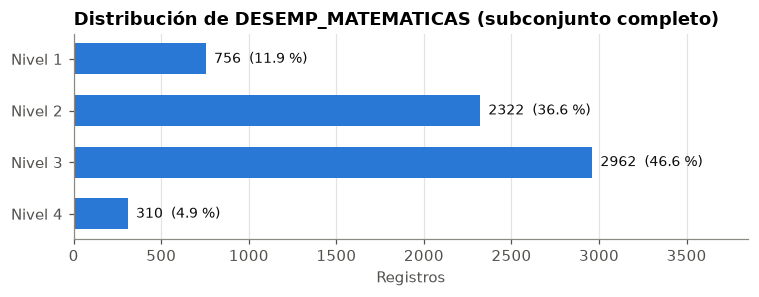

In [69]:
def graficar_distribucion_clases(y, titulo="Distribución de clases", ax=None):
    """Barras horizontales con el número de registros por clase y su porcentaje.
    Se reutiliza para mostrar las versiones balanceadas y desbalanceadas."""
    y = pd.Series(y)
    if pd.api.types.is_numeric_dtype(y):          # etiquetas codificadas 0..3 -> nombres
        y = y.map(dict(enumerate(CLASES)))
    conteo = y.value_counts().reindex(CLASES, fill_value=0)
    pct = conteo / conteo.sum() * 100
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(conteo.index, conteo.values, color=COLOR_PRINCIPAL, height=0.6)
    for i, (n, p) in enumerate(zip(conteo.values, pct.values)):
        ax.text(n, i, f"  {n}  ({p:.1f} %)", va="center", color="#0b0b0b", fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, conteo.max() * 1.3)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Registros")
    ax.set_title(titulo, loc="left")
    return ax


tabla_clases = pd.DataFrame({
    "Registros": df[OBJETIVO].value_counts().reindex(CLASES),
    "%": (df[OBJETIVO].value_counts(normalize=True).reindex(CLASES) * 100).round(2),
})
display(tabla_clases)
graficar_distribucion_clases(df[OBJETIVO], "Distribución de DESEMP_MATEMATICAS (subconjunto completo)")
plt.tight_layout()
plt.show()

### 3.3 Estadísticas descriptivas

In [70]:
print("Variables numéricas:")
display(df[VARIABLES_NUMERICAS].describe().T.round(2))

print("Variables categóricas:")
display(df.drop(columns=VARIABLES_NUMERICAS).describe().T)

Variables numéricas:


,count,mean,std,min,25%,50%,75%,max
PUNT_LECTURA_CRITICA,6350.0,52.99,10.81,0.0,45.0,53.0,61.0,100.0
PUNT_C_NATURALES,6350.0,48.99,10.47,25.0,41.0,48.0,56.0,100.0
PUNT_SOCIALES_CIUDADANAS,6350.0,47.72,12.02,19.0,38.0,47.0,57.0,100.0
PUNT_INGLES,6320.0,50.19,13.36,0.0,39.0,49.0,59.0,100.0
EDAD,6345.0,17.30,2.94,13.0,16.0,17.0,18.0,67.0


Variables categóricas:


,count,unique,top,freq
COLE_AREA_UBICACION,6350,2,URBANO,5272
COLE_BILINGUE,5224,2,N,5135
COLE_CARACTER,6079,4,ACADÉMICO,3265
COLE_DEPTO_UBICACION,6350,33,BOGOTÁ,968
COLE_GENERO,6350,3,MIXTO,6184
COLE_JORNADA,6350,6,MAÑANA,2492
COLE_NATURALEZA,6350,2,OFICIAL,4780
COLE_SEDE_PRINCIPAL,6350,2,S,6006
ESTU_GENERO,6350,2,F,3421
FAMI_CUARTOSHOGAR,6054,6,Dos,2344


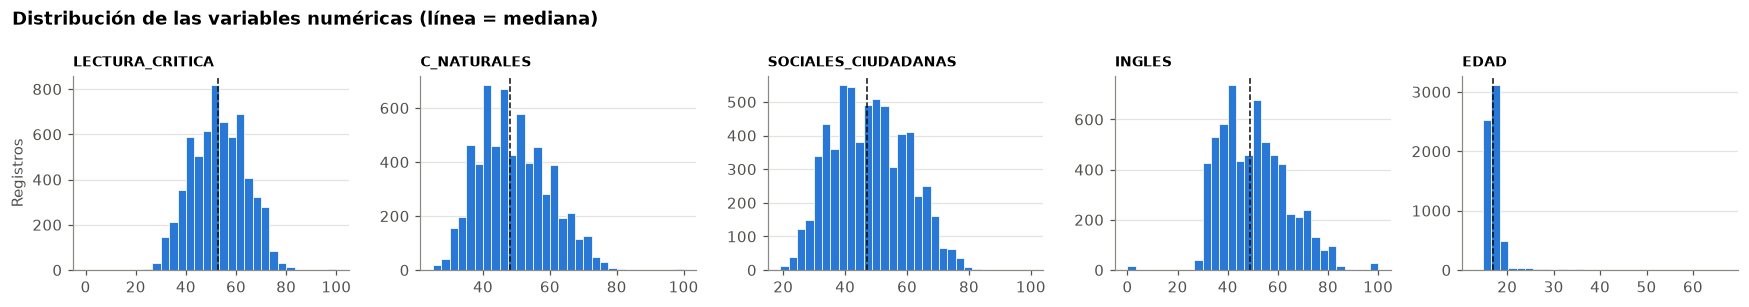

In [71]:
def graficar_histogramas(df, columnas, titulo):
    """Histogramas de las variables numéricas (uno por panel), con la mediana marcada."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(3.2 * len(columnas), 2.8))
    for ax, col in zip(axes, columnas):
        datos = df[col].dropna()
        ax.hist(datos, bins=30, color=COLOR_PRINCIPAL, edgecolor="white", linewidth=0.5)
        ax.axvline(datos.median(), color="#0b0b0b", linestyle="--", linewidth=1)
        ax.set_title(col.replace("PUNT_", ""), fontsize=9, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Registros")
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_histogramas(df, VARIABLES_NUMERICAS, "Distribución de las variables numéricas (línea = mediana)")

### 3.4 Valores nulos

Variables con nulos: 13 de 24
Filas con al menos un nulo: 2161 (34.0%)


,Nulos,%
COLE_BILINGUE,1126,17.73
FAMI_EDUCACIONPADRE,877,13.81
FAMI_EDUCACIONMADRE,525,8.27
FAMI_ESTRATOVIVIENDA,448,7.06
FAMI_TIENEINTERNET,370,5.83
FAMI_TIENEAUTOMOVIL,305,4.80
FAMI_CUARTOSHOGAR,296,4.66
FAMI_TIENELAVADORA,290,4.57
FAMI_TIENECOMPUTADOR,288,4.54
FAMI_PERSONASHOGAR,287,4.52


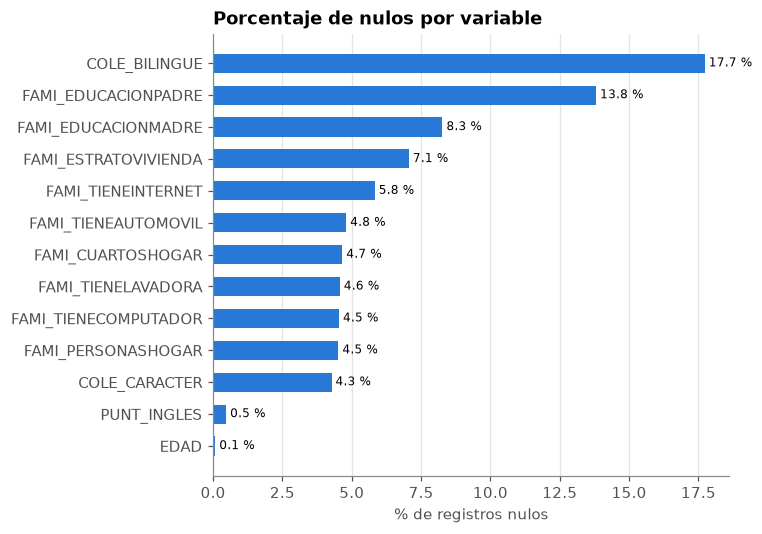

In [72]:
def tabla_nulos(df):
    """Cantidad y porcentaje de nulos por variable (solo las que tienen nulos)."""
    nulos = df.isna().sum()
    tabla = pd.DataFrame({"Nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
    return tabla[tabla["Nulos"] > 0].sort_values("Nulos", ascending=False)


nulos = tabla_nulos(df)
filas_con_nulos = df.isna().any(axis=1).sum()
print(f"Variables con nulos: {len(nulos)} de {df.shape[1]}")
print(f"Filas con al menos un nulo: {filas_con_nulos} ({filas_con_nulos / len(df):.1%})")
display(nulos)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(nulos) + 0.8))
ax.barh(nulos.index, nulos["%"], color=COLOR_PRINCIPAL, height=0.6)
for i, p in enumerate(nulos["%"]):
    ax.text(p, i, f" {p:.1f} %", va="center", fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de registros nulos")
ax.set_title("Porcentaje de nulos por variable", loc="left")
plt.tight_layout()
plt.show()

Antes de decidir entre eliminar e imputar, comparamos las filas que tienen algún nulo con las filas completas.

In [73]:
def comparar_filas_con_nulos(df, columnas=("COLE_AREA_UBICACION", "COLE_NATURALEZA")):
    """Compara la distribución del objetivo y de algunas variables de contexto entre
    las filas con al menos un nulo y las filas completas (% por fila)."""
    tiene_nulo = df.isna().any(axis=1).map({False: "Sin nulos", True: "Con nulos"})
    tablas = [pd.crosstab(tiene_nulo, df[OBJETIVO], normalize="index")]
    tablas += [pd.crosstab(tiene_nulo, df[c], normalize="index") for c in columnas]
    tabla = (pd.concat(tablas, axis=1) * 100).round(1)
    tabla.insert(0, "Registros", tiene_nulo.value_counts())
    tabla.index.name = None
    return tabla


comparar_filas_con_nulos(df)

,Registros,Nivel 1,Nivel 2,Nivel 3,Nivel 4,RURAL,URBANO,NO OFICIAL,OFICIAL
Con nulos,2161,14.8,39.5,41.7,4.0,21.9,78.1,30.3,69.7
Sin nulos,4189,10.4,35.1,49.2,5.3,14.4,85.6,21.9,78.1


**Los nulos no son aleatorios.** Las filas con nulos tienen más Nivel 1 (14.8 % frente a 10.4 %), menos Nivel 3 (41.7 % frente a 49.2 %) y más colegios rurales (21.9 % frente a 14.4 %).

**Decisión: imputar en lugar de eliminar.**
- Las filas con algún nulo son el 34 % del subconjunto.
- Eliminarlas sesgaría la muestra contra los estudiantes rurales y de bajo desempeño, y reduciría de forma desproporcionada a Nivel 1, que ya es una clase minoritaria.
- Ninguna variable supera el ~18 % de nulos, así que la imputación no distorsiona de forma importante las distribuciones.

Por la misma razón, descartamos extraer el subconjunto solo de filas completas: equivale a eliminar esas filas antes del muestreo y produce el mismo sesgo.

**Imputación:**
- **Categóricas:** moda.
- **Numéricas** (`PUNT_INGLES` y `EDAD`): mediana, porque es robusta a la cola de valores altos de `EDAD`.
- Ambas se calculan **solo con el entrenamiento** (sección 4.2).

### 3.5 Matriz de correlación
La matriz incluye las variables numéricas, las ordinales (codificadas según su orden) y el objetivo (Nivel 1 → 1, …, Nivel 4 → 4). Las nominales no se incluyen porque no tienen orden.

Usamos **Spearman** en lugar de Pearson porque 5 de las variables y el objetivo son ordinales, y lo que se espera de ellas es una relación monótona, no necesariamente lineal. El análisis es descriptivo y no interviene en el preprocesamiento.

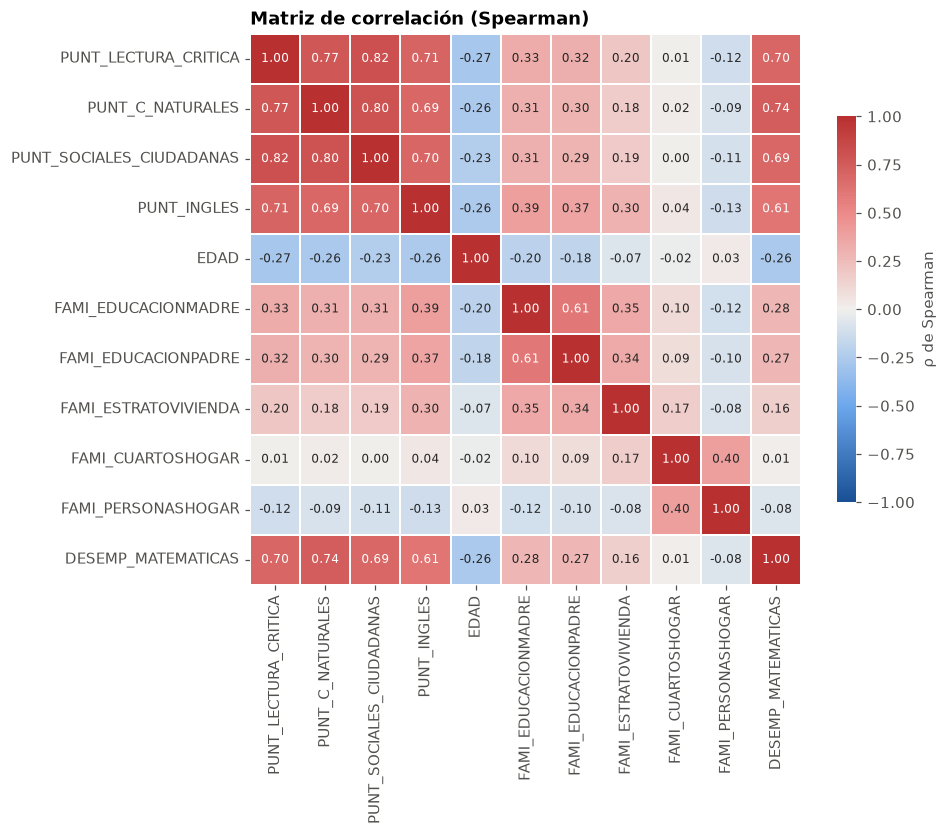

Correlación de cada variable con el objetivo:


PUNT_C_NATURALES            0.744
PUNT_LECTURA_CRITICA        0.700
PUNT_SOCIALES_CIUDADANAS    0.694
PUNT_INGLES                 0.609
FAMI_EDUCACIONMADRE         0.275
FAMI_EDUCACIONPADRE         0.274
FAMI_ESTRATOVIVIENDA        0.161
FAMI_CUARTOSHOGAR           0.014
FAMI_PERSONASHOGAR         -0.075
EDAD                       -0.261
Name: DESEMP_MATEMATICAS, dtype: float64

In [74]:
def codificar_ordinales_para_eda(df):
    """Versión numérica del dataset solo para el EDA: ordinales y objetivo
    reemplazados por su posición en el orden (los nulos se mantienen como NaN)."""
    datos = df[VARIABLES_NUMERICAS].copy()
    for col, orden in VARIABLES_ORDINALES.items():
        datos[col] = df[col].map({v: i for i, v in enumerate(orden)})
    datos[OBJETIVO] = df[OBJETIVO].map({c: i + 1 for i, c in enumerate(CLASES)})
    return datos


datos_corr = codificar_ordinales_para_eda(df)
matriz_corr = datos_corr.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="white", square=True,
            annot_kws={"fontsize": 8}, cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Matriz de correlación (Spearman)", loc="left")
ax.grid(False)
plt.tight_layout()
plt.show()

print("Correlación de cada variable con el objetivo:")
matriz_corr[OBJETIVO].drop(OBJETIVO).sort_values(ascending=False).round(3)

### 3.6 Hallazgos del EDA
- **Desbalance natural de las clases.** Nivel 3 (46.6 %) y Nivel 2 (36.6 %) suman el 83 %, y Nivel 4 tiene apenas el 4.9 %. Un clasificador que siempre prediga Nivel 3 alcanzaría ~47 % de accuracy, por lo que priorizamos el **F1 macro** y el **recall por clase**.
- **Predictores principales.** Los puntajes de las otras áreas tienen ρ entre 0.61 y 0.74 con el objetivo. Les siguen la educación de los padres (ρ ≈ 0.27) y el estrato (ρ ≈ 0.16).
- **La edad tiene correlación negativa** (ρ ≈ −0.26). En las jornadas nocturna y sabatina, cerca de un tercio de los estudiantes tiene 20 años o más.
- **Los puntajes están correlacionados entre sí** (ρ entre 0.69 y 0.82). Lo tendremos en cuenta al interpretar la importancia de variables del árbol, donde esa importancia se reparte entre ellos.
- **Hay atípicos.** `EDAD` alcanza 67 años (mediana de 17) y hay puntajes de 0 y de 100. Se tratan en la sección 4.5.

## 4. Partición y preprocesamiento: las 8 versiones de la Figura 1
Todo ajuste que aprende de los datos (imputación, codificación, límites de outliers, balanceo y escalado) se hace **solo con el entrenamiento**. Validación y prueba solo se transforman: no se balancean ni se les modifican los outliers, para que conserven la distribución real. **El conjunto de prueba es el mismo en los 8 casos**; entre casos solo cambia si está escalado.

| Paso | Qué se hace | Se ajusta con |
|---|---|---|
| 1. Partición | 70 / 15 / 15 estratificada, `random_state = 79` | — (una sola vez) |
| 2. Imputación | Mediana (numéricas) y moda (categóricas) | Entrenamiento base |
| 3. Outliers NO | Se **eliminan** las filas detectadas con IQR | Límites IQR del entrenamiento base |
| 4. CC ordinal | Cada ordinal se reemplaza por su posición en el orden del dominio | Orden fijo (no aprende de los datos) |
| 5. Balanceo | NO → submuestreo a ~70 % de Nivel 3 · SI → SMOTENC | Entrenamiento del caso |
| 6. Outliers SI | Se conservan los reales y se **inyectan** sintéticos hasta llegar al 5 % | Límites IQR del entrenamiento base |
| 7. CC One-Hot | Variables nominales | Entrenamiento base |
| 8. ED | StandardScaler sobre numéricas y ordinales (solo casos 5–8) | Entrenamiento del caso |

**Orden de los pasos:**
- **Los outliers se eliminan antes de balancear**, para que SMOTE no genere registros a partir de atípicos en las versiones sin outliers.
- **Se balancea antes de escalar**, para que los casos *k* y *k+4* tengan los mismos registros. Así la diferencia entre "ED NO" y "ED SI" se debe únicamente al escalado.
- **Los outliers se inyectan después de balancear**, para garantizar que sean el 5 % del entrenamiento final. Si se inyectaran antes, el submuestreo o SMOTE alterarían ese porcentaje.

### 4.1 Partición estratificada 70 / 15 / 15
La partición se hace una sola vez y estratificada, para que los tres conjuntos conserven la proporción de clases. Las etiquetas se codifican como enteros (Nivel 1 → 0, …, Nivel 4 → 3), que es el formato común a todos los modelos (incluida la red neuronal) y a las curvas ROC. Los nombres se conservan en `CLASES`.

In [75]:
def particionar(df, semilla=SEMILLA):
    """Divide el dataset limpio en entrenamiento (70 %), validación (15 %) y prueba (15 %),
    estratificando por la etiqueta. Retorna X_train, X_val, X_test, y_train, y_val, y_test."""
    X = df.drop(columns=OBJETIVO)
    y = df[OBJETIVO].map({c: i for i, c in enumerate(CLASES)}).astype(int)
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=semilla)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=semilla)
    return X_train, X_val, X_test, y_train, y_val, y_test


X_train_0, X_val_0, X_test_0, y_train_0, y_val_0, y_test_0 = particionar(df)
# La partición coincide con la usada en la limpieza para detectar casi constantes (sección 2)
assert set(X_train_0.index) == set(INDICES_TRAIN), "La partición no coincide con INDICES_TRAIN"

resumen_particion = pd.DataFrame({
    nombre: {"Registros": len(y), "% del total": round(len(y) / len(df) * 100, 1),
             **{c: f"{p:.1f} %" for c, p in zip(CLASES, y.value_counts(normalize=True).sort_index() * 100)}}
    for nombre, y in [("Entrenamiento", y_train_0), ("Validación", y_val_0), ("Prueba", y_test_0)]
}).T
resumen_particion

,Registros,% del total,Nivel 1,Nivel 2,Nivel 3,Nivel 4
Entrenamiento,4445,70.0,11.9 %,36.6 %,46.7 %,4.9 %
Validación,952,15.0,11.9 %,36.6 %,46.6 %,4.9 %
Prueba,953,15.0,12.0 %,36.6 %,46.6 %,4.8 %


### 4.2 Imputación de nulos
Moda para las categóricas y mediana para las numéricas, ambas calculadas con el entrenamiento (justificación en la sección 3.4).

In [76]:
def ajustar_imputacion(X_train):
    """Calcula el valor de relleno de cada columna con el entrenamiento:
    la mediana si es numérica y la moda si es categórica."""
    return {col: (X_train[col].median() if col in VARIABLES_NUMERICAS else X_train[col].mode()[0])
            for col in X_train.columns}


def aplicar_imputacion(X, valores):
    """Rellena los nulos de X con los valores aprendidos en el entrenamiento."""
    return X.fillna(value=valores)


VALORES_IMPUTACION = ajustar_imputacion(X_train_0)
X_train_imp = aplicar_imputacion(X_train_0, VALORES_IMPUTACION)
X_val_imp = aplicar_imputacion(X_val_0, VALORES_IMPUTACION)
X_test_imp = aplicar_imputacion(X_test_0, VALORES_IMPUTACION)

print("Nulos restantes -> train:", X_train_imp.isna().sum().sum(),
      "| val:", X_val_imp.isna().sum().sum(), "| test:", X_test_imp.isna().sum().sum())
pd.Series({c: VALORES_IMPUTACION[c] for c in tabla_nulos(df).index}, name="Valor de imputación").to_frame()

Nulos restantes -> train: 0 | val: 0 | test: 0


,Valor de imputación
COLE_BILINGUE,N
FAMI_EDUCACIONPADRE,Secundaria (Bachillerato) completa
FAMI_EDUCACIONMADRE,Secundaria (Bachillerato) completa
FAMI_ESTRATOVIVIENDA,Estrato 2
FAMI_TIENEINTERNET,Si
FAMI_TIENEAUTOMOVIL,No
FAMI_CUARTOSHOGAR,Dos
FAMI_TIENELAVADORA,Si
FAMI_TIENECOMPUTADOR,Si
FAMI_PERSONASHOGAR,3 a 4


### 4.3 Conversión de categóricas (CC)
- **Codificación ordinal** para las 5 variables con orden natural: educación de la madre y del padre (de *Ninguno* a *Postgrado*), estrato, cuartos y personas del hogar. Así se conserva el orden en una sola columna por variable.
  - Ubicamos *Sin Estrato* en la posición más baja porque los datos lo respaldan: el 45 % de esos registros corresponde a colegios rurales (21 % en Estrato 1) y tiene el peor desempeño (31 % en Nivel 1, frente a 13 % en Estrato 1).
- **One-Hot** para las 13 nominales. Una codificación numérica impondría un orden y unas distancias que no existen entre sus categorías, lo que afectaría a KNN, SVM y las redes.
  - `drop="if_binary"` deja una sola columna por variable binaria, porque la segunda sería redundante.
  - `handle_unknown="ignore"` codifica con ceros una categoría que no aparezca en el entrenamiento, en vez de generar un error.
- **El One-Hot se ajusta una sola vez**, con el entrenamiento base, para que los 8 casos tengan las mismas 65 columnas. Si se ajustara por caso, una categoría poco frecuente podría desaparecer con el submuestreo y las columnas dejarían de coincidir entre casos.

In [77]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def codificar_ordinales(X):
    """Reemplaza cada variable ordinal por su posición (0, 1, 2, ...) en el orden
    definido en VARIABLES_ORDINALES."""
    X = X.copy()
    for col, orden in VARIABLES_ORDINALES.items():
        X[col] = X[col].map({v: i for i, v in enumerate(orden)}).astype(int)
    return X


def ajustar_one_hot(X_train):
    """Ajusta el codificador One-Hot de las variables nominales con el entrenamiento."""
    encoder = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)
    encoder.fit(X_train[VARIABLES_NOMINALES])
    return encoder


def aplicar_one_hot(X, encoder):
    """Aplica el One-Hot a las nominales y conserva numéricas y ordinales.
    Retorna un DataFrame con nombres de columna legibles."""
    dummies = pd.DataFrame(encoder.transform(X[VARIABLES_NOMINALES]),
                           columns=encoder.get_feature_names_out(VARIABLES_NOMINALES),
                           index=X.index)
    return pd.concat([X[VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES)], dummies], axis=1)


X_train_base = codificar_ordinales(X_train_imp)     # entrenamiento base: imputado + ordinal
X_val_base = codificar_ordinales(X_val_imp)
X_test_base = codificar_ordinales(X_test_imp)
ENCODER_OH = ajustar_one_hot(X_train_base)

COLUMNAS_A_ESCALAR = VARIABLES_NUMERICAS + list(VARIABLES_ORDINALES)
print(f"Columnas tras CC: {aplicar_one_hot(X_train_base.head(), ENCODER_OH).shape[1]} "
      f"({len(VARIABLES_NUMERICAS)} numéricas + {len(VARIABLES_ORDINALES)} ordinales + "
      f"{len(ENCODER_OH.get_feature_names_out())} dummies One-Hot)")
X_train_base[list(VARIABLES_ORDINALES)].head()

Columnas tras CC: 65 (5 numéricas + 5 ordinales + 55 dummies One-Hot)


,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA,FAMI_CUARTOSHOGAR,FAMI_PERSONASHOGAR
420,5,6,1,3,2
1533,4,4,2,1,1
5011,4,4,2,1,1
5166,4,6,2,1,1
2560,3,4,0,1,1


### 4.4 Escalado (ED)
Elegimos **StandardScaler** por dos razones:
- KNN y SVM dependen de distancias y las redes se entrenan por gradiente. Sin escalar, `EDAD` (13–67) y los puntajes (0–100) dominarían sobre las variables binarias (0/1).
- Frente a MinMaxScaler, se distorsiona menos con outliers. En MinMax, un solo valor extremo fija el máximo y comprime al resto de los valores, y los casos 7 y 8 incluyen outliers.

Se escalan solo las numéricas y las ordinales. Las dummies se mantienen en 0/1 porque ya están acotadas y así siguen siendo interpretables. El escalador se ajusta con el entrenamiento **de cada caso**, porque cada caso tiene registros distintos.

In [78]:
def ajustar_escalado(X_train, columnas=COLUMNAS_A_ESCALAR):
    """Ajusta un StandardScaler sobre las columnas indicadas del entrenamiento."""
    return StandardScaler().fit(X_train[columnas])


def aplicar_escalado(X, scaler, columnas=COLUMNAS_A_ESCALAR):
    """Aplica el escalador ya ajustado a las columnas indicadas; el resto queda igual."""
    X = X.copy()
    X[columnas] = scaler.transform(X[columnas])
    return X

### 4.5 Outliers
- **Detección:** IQR con factor 1.5, sobre las 5 variables numéricas. Lo preferimos a Z-score porque no supone normalidad: `EDAD` es muy asimétrica, y en ese caso la media y la desviación estándar se inflan con los mismos valores que se quieren detectar. En las ordinales y las dummies no aplica, porque tienen pocos valores posibles.
- **Límites:** se calculan una sola vez, con el entrenamiento base ya imputado.

In [79]:
# Rango posible de cada variable numérica (los valores inyectados deben ser plausibles)
DOMINIO_NUMERICAS = {"PUNT_LECTURA_CRITICA": (0, 100), "PUNT_C_NATURALES": (0, 100),
                     "PUNT_SOCIALES_CIUDADANAS": (0, 100), "PUNT_INGLES": (0, 100),
                     "EDAD": (EDAD_MIN, EDAD_MAX)}   # mismo rango que la limpieza de EDAD
PROPORCION_OUTLIERS = 0.05


def calcular_limites_iqr(X, columnas=VARIABLES_NUMERICAS, factor=1.5):
    """Calcula Q1, Q3, IQR y los límites inferior y superior de cada columna."""
    q1, q3 = X[columnas].quantile(0.25), X[columnas].quantile(0.75)
    iqr = q3 - q1
    return pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                         "Límite inferior": q1 - factor * iqr,
                         "Límite superior": q3 + factor * iqr})


def detectar_outliers(X, limites):
    """Retorna una máscara booleana: True si la fila tiene al menos un valor fuera de los límites."""
    columnas = limites.index
    fuera = (X[columnas] < limites["Límite inferior"]) | (X[columnas] > limites["Límite superior"])
    return fuera.any(axis=1)


LIMITES_IQR = calcular_limites_iqr(X_train_base)
mascara_base = detectar_outliers(X_train_base, LIMITES_IQR)
tabla_outliers = LIMITES_IQR.copy()
tabla_outliers["Outliers en train"] = [
    ((X_train_base[c] < LIMITES_IQR.loc[c, "Límite inferior"]) |
     (X_train_base[c] > LIMITES_IQR.loc[c, "Límite superior"])).sum() for c in LIMITES_IQR.index]
print(f"Filas de entrenamiento con al menos un outlier: {mascara_base.sum()} "
      f"de {len(X_train_base)} ({mascara_base.mean():.2%})")
tabla_outliers.round(2)

Filas de entrenamiento con al menos un outlier: 137 de 4445 (3.08%)


,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers en train
PUNT_LECTURA_CRITICA,45.0,61.0,16.0,21.0,85.0,5
PUNT_C_NATURALES,41.0,57.0,16.0,17.0,81.0,2
PUNT_SOCIALES_CIUDADANAS,38.0,57.0,19.0,9.5,85.5,0
PUNT_INGLES,39.0,59.0,20.0,9.0,89.0,25
EDAD,16.0,18.0,2.0,13.0,21.0,107


**Sin outliers:** eliminamos las filas detectadas, que son ~3 % del entrenamiento. No las winsorizamos porque eso alteraría valores reales; por ejemplo, un estudiante de 40 años pasaría a tener 21.

**Con outliers (5 %):** conservamos los outliers reales, porque forman parte del dominio (adultos de jornadas nocturna y sabatina, puntajes de 0 y de 100), e inyectamos outliers sintéticos hasta completar el 5 % exacto del entrenamiento final. La inyección:
1. Selecciona al azar (semilla 79) filas que no son atípicas.
2. Modifica 1 o 2 de sus variables numéricas, elegidas al azar.
3. Les asigna un valor uniforme dentro de la zona atípica: fuera de los límites IQR, pero dentro del rango posible de la variable (0–100 para los puntajes y 13–80 para la edad, el mismo rango de la limpieza). Así cada valor inyectado es detectable como atípico y a la vez plausible.

En los casos balanceados se necesitan menos outliers inyectados, porque SMOTE ya genera atípicos. Al sobremuestrear Nivel 1, que concentra la extraedad (el 9.7 % tiene más de 21 años, frente a 0 % en Nivel 4), produce registros sintéticos con edades atípicas.

In [80]:
def eliminar_outliers(X, y, limites=None):
    """Elimina las filas con al menos un outlier (IQR). Retorna X, y y la cantidad eliminada."""
    limites = LIMITES_IQR if limites is None else limites
    mascara = detectar_outliers(X, limites)
    return X[~mascara], y[~mascara], int(mascara.sum())


def inyectar_outliers(X, y, proporcion=PROPORCION_OUTLIERS, limites=None, semilla=SEMILLA):
    """Completa los outliers del entrenamiento hasta que representen `proporcion` de las filas.

    Conserva los outliers ya presentes (reales o generados por SMOTE) e inyecta los faltantes modificando filas no atípicas:
    a cada fila elegida se le cambian 1 o 2 variables numéricas por un valor entero
    uniforme en la zona atípica (fuera de los límites IQR, dentro de DOMINIO_NUMERICAS).
    Retorna X, y y un diccionario con el reporte (reales, inyectados, total, %)."""
    limites = LIMITES_IQR if limites is None else limites
    rng = np.random.default_rng(semilla)
    X = X.copy()
    X[VARIABLES_NUMERICAS] = X[VARIABLES_NUMERICAS].astype(float)

    mascara = detectar_outliers(X, limites)
    n_reales = int(mascara.sum())
    n_objetivo = int(np.ceil(proporcion * len(X)))
    n_inyectar = max(0, n_objetivo - n_reales)

    filas = rng.choice(np.where(~mascara.values)[0], size=n_inyectar, replace=False)
    variables_usadas = []
    for fila in filas:
        columnas = rng.choice(VARIABLES_NUMERICAS, size=rng.integers(1, 3), replace=False)
        for col in columnas:
            minimo, maximo = DOMINIO_NUMERICAS[col]
            bajo = (minimo, int(np.ceil(limites.loc[col, "Límite inferior"])) - 1)
            alto = (int(np.floor(limites.loc[col, "Límite superior"])) + 1, maximo)
            zonas = [z for z in (bajo, alto) if z[0] <= z[1]]          # zonas no vacías
            inicio, fin = zonas[rng.integers(len(zonas))]
            X.iloc[fila, X.columns.get_loc(col)] = rng.integers(inicio, fin + 1)
            variables_usadas.append(col)

    total = int(detectar_outliers(X, limites).sum())
    reporte = {"Outliers previos": n_reales, "Outliers inyectados": n_inyectar,
               "Outliers totales": total, "% outliers": round(total / len(X) * 100, 2),
               "Variables modificadas": pd.Series(variables_usadas, dtype=str).value_counts().to_dict()}
    return X, y, reporte

### 4.6 Balanceo
**Desbalanceado (Balanceo NO): submuestreo a 70 / 10 / 10 / 10.**
- Tomamos Nivel 3 como clase mayoritaria porque ya lo es en los datos (46.6 %).
- Solo usamos registros reales. Nivel 4 (~210 registros en entrenamiento) define el 10 %: se toma la misma cantidad de Nivel 1 y de Nivel 2, y siete veces esa cantidad de Nivel 3.

**Balanceado (Balanceo SI): SMOTENC hasta igualar la clase mayoritaria.** Elegimos SMOTENC frente a las demás opciones:
- **Frente a duplicar registros:** la duplicación favorece el sobreajuste, porque el modelo ve los mismos registros varias veces.
- **Frente al submuestreo:** dejaría ~210 registros por clase y descartaría cerca del 80 % de los datos.
- **Frente al SMOTE clásico:** interpolaría las variables One-Hot y produciría categorías inexistentes. SMOTENC asigna a cada variable nominal la categoría más frecuente entre los vecinos. Las ordinales sintéticas se redondean al nivel más cercano.

Ambas técnicas se aplican solo al entrenamiento.

In [81]:
from imblearn.over_sampling import SMOTENC

CLASE_MAYORITARIA = CLASES.index("Nivel 3")   # código 2
PROPORCION_MAYORITARIA = 0.70


def desbalancear(X, y, clase_mayoritaria=CLASE_MAYORITARIA,
                 proporcion=PROPORCION_MAYORITARIA, semilla=SEMILLA):
    """Submuestrea para que la clase mayoritaria tenga `proporcion` de los registros y
    las demás se repartan el resto en partes iguales. La clase minoritaria más pequeña
    determina cuántos registros toma cada clase no mayoritaria."""
    conteos = y.value_counts()
    otras = [c for c in conteos.index if c != clase_mayoritaria]
    n_otra = conteos[otras].min()
    n_mayor = int(round(n_otra * len(otras) * proporcion / (1 - proporcion)))
    if n_mayor > conteos[clase_mayoritaria]:          # si no alcanza la mayoritaria, se recorta el resto
        n_mayor = conteos[clase_mayoritaria]
        n_otra = int(round(n_mayor * (1 - proporcion) / (proporcion * len(otras))))
    objetivo = {clase_mayoritaria: n_mayor, **{c: n_otra for c in otras}}
    indices = pd.concat([y[y == c].sample(n=n, random_state=semilla) for c, n in objetivo.items()]).index
    indices = indices.to_series().sample(frac=1, random_state=semilla).index   # mezclar el orden
    return X.loc[indices], y.loc[indices]


def balancear_smote(X, y, semilla=SEMILLA, k_vecinos=5):
    """Balancea con SMOTENC (nominales como categóricas) hasta igualar todas las clases
    a la mayoritaria. Redondea las ordinales al entero más cercano."""
    indices_nominales = [X.columns.get_loc(c) for c in VARIABLES_NOMINALES]
    smote = SMOTENC(categorical_features=indices_nominales, k_neighbors=k_vecinos,
                    random_state=semilla)
    X_res, y_res = smote.fit_resample(X, y)
    X_res = pd.DataFrame(X_res, columns=X.columns)
    for col, orden in VARIABLES_ORDINALES.items():
        X_res[col] = X_res[col].round().clip(0, len(orden) - 1).astype(int)
    return X_res, pd.Series(y_res, name=y.name)

### 4.7 Construcción de los 8 casos
`construir_casos()` devuelve `casos[1..8]`, el formato común para los bloques 2, 3 y 4:

| Clave | Contenido |
|---|---|
| `X_train`, `X_val`, `X_test` | DataFrames codificados (y escalados en los casos 5–8) |
| `y_train`, `y_val`, `y_test` | Series de enteros 0–3 (`CLASES[i]` da el nombre) |
| `normalizacion`, `outliers`, `balanceo` | La fila correspondiente de la Figura 1 |
| `scaler` | El StandardScaler ajustado, o `None` |
| `reporte` | Registros eliminados o inyectados y distribución de clases |

In [82]:
# Configuración de la Figura 1: (ED, outliers, balanceo)
CONFIG_CASOS = {
    1: (False, False, False), 2: (False, False, True),
    3: (False, True,  False), 4: (False, True,  True),
    5: (True,  False, False), 6: (True,  False, True),
    7: (True,  True,  False), 8: (True,  True,  True),
}


def construir_caso(numero):
    """Construye el caso `numero` de la Figura 1 a partir del entrenamiento base
    (imputado y con ordinales codificados) y lo devuelve como diccionario."""
    escalado, con_outliers, balanceado = CONFIG_CASOS[numero]
    X, y = X_train_base.copy(), y_train_0.copy()
    reporte = {}

    # Outliers NO: se eliminan antes de balancear
    if not con_outliers:
        X, y, reporte["Filas eliminadas (outliers)"] = eliminar_outliers(X, y)

    # Balanceo
    X, y = balancear_smote(X, y) if balanceado else desbalancear(X, y)

    # Outliers SI: se completan hasta el 5 % del entrenamiento final
    if con_outliers:
        X, y, rep = inyectar_outliers(X, y)
        reporte.update(rep)
    reporte["% outliers (IQR)"] = round(detectar_outliers(X, LIMITES_IQR).mean() * 100, 2)

    # CC One-Hot (mismo codificador para todos los casos)
    X_train = aplicar_one_hot(X, ENCODER_OH)
    X_val = aplicar_one_hot(X_val_base, ENCODER_OH)
    X_test = aplicar_one_hot(X_test_base, ENCODER_OH)

    # ED: StandardScaler ajustado con el entrenamiento del caso
    scaler = None
    if escalado:
        scaler = ajustar_escalado(X_train)
        X_train, X_val, X_test = (aplicar_escalado(d, scaler) for d in (X_train, X_val, X_test))

    reporte["Distribución train"] = (y.value_counts().sort_index()
                                     .rename(index=dict(enumerate(CLASES))).to_dict())
    return {
        "X_train": X_train.reset_index(drop=True), "y_train": y.reset_index(drop=True),
        "X_val": X_val, "y_val": y_val_0, "X_test": X_test, "y_test": y_test_0,
        "normalizacion": f"CC(SI) y ED({'SI' if escalado else 'NO'})",
        "outliers": "SI" if con_outliers else "NO",
        "balanceo": "SI" if balanceado else "NO",
        "scaler": scaler, "reporte": reporte,
    }


def construir_casos():
    """Construye los 8 casos de la Figura 1. Retorna el diccionario casos[1..8]."""
    fijar_semillas()
    return {numero: construir_caso(numero) for numero in CONFIG_CASOS}


casos = construir_casos()

### 4.8 Verificación y resumen de los 8 casos

In [83]:
def resumen_casos(casos):
    """Tabla resumen de los 8 casos: configuración, tamaño, distribución de clases y % de outliers."""
    filas = []
    for k, c in casos.items():
        dist = c["y_train"].value_counts(normalize=True).sort_index() * 100
        filas.append({
            "Caso": k, "Normalización": c["normalizacion"], "Outliers": c["outliers"],
            "Balanceo": c["balanceo"], "Registros train": len(c["y_train"]),
            **{c_: f"{p:.1f} %" for c_, p in zip(CLASES, dist)},
            "% outliers": c["reporte"]["% outliers (IQR)"],
            "Inyectados": c["reporte"].get("Outliers inyectados", 0),
            "Eliminados": c["reporte"].get("Filas eliminadas (outliers)", 0),
            "Columnas": c["X_train"].shape[1],
            "Filas por columna": round(len(c["y_train"]) / c["X_train"].shape[1], 1),
        })
    return pd.DataFrame(filas).set_index("Caso")


# Verificaciones de consistencia
for k, c in casos.items():
    assert c["y_test"].equals(y_test_0), "El conjunto de prueba debe ser el mismo en los 8 casos"
    assert list(c["X_test"].index) == list(X_test_0.index)
    assert c["X_train"].isna().sum().sum() == 0
for k in range(1, 5):   # casos k y k+4 solo difieren en el escalado
    assert casos[k]["y_train"].equals(casos[k + 4]["y_train"])
print("Verificaciones OK: prueba idéntica en los 8 casos, sin nulos, casos k y k+4 con los mismos registros.")

resumen_casos(casos)

Verificaciones OK: prueba idéntica en los 8 casos, sin nulos, casos k y k+4 con los mismos registros.


,Normalización,Outliers,Balanceo,Registros train,Nivel 1,Nivel 2,Nivel 3,Nivel 4,% outliers,Inyectados,Eliminados,Columnas,Filas por columna
Caso,,,,,,,,,,,,,
1,CC(SI) y ED(NO),NO,NO,2050,10.0 %,10.0 %,70.0 %,10.0 %,0.00,0,137,65,31.5
2,CC(SI) y ED(NO),NO,SI,8208,25.0 %,25.0 %,25.0 %,25.0 %,0.00,0,137,65,126.3
3,CC(SI) y ED(NO),SI,NO,2170,10.0 %,10.0 %,70.0 %,10.0 %,5.02,54,0,65,33.4
4,CC(SI) y ED(NO),SI,SI,8296,25.0 %,25.0 %,25.0 %,25.0 %,5.00,47,0,65,127.6
5,CC(SI) y ED(SI),NO,NO,2050,10.0 %,10.0 %,70.0 %,10.0 %,0.00,0,137,65,31.5
6,CC(SI) y ED(SI),NO,SI,8208,25.0 %,25.0 %,25.0 %,25.0 %,0.00,0,137,65,126.3
7,CC(SI) y ED(SI),SI,NO,2170,10.0 %,10.0 %,70.0 %,10.0 %,5.02,54,0,65,33.4
8,CC(SI) y ED(SI),SI,SI,8296,25.0 %,25.0 %,25.0 %,25.0 %,5.00,47,0,65,127.6


**Tamaño de los casos desbalanceados (~2050–2170 registros).** Consideramos que es suficiente:
1. **Validación y prueba no cambian:** todos los casos se evalúan con los mismos 953 registros de prueba.
2. **Hay ~32 registros por columna** (65 columnas).
3. **El tamaño es adecuado para cada modelo:**

| Modelo | ¿Alcanza con ~2100 filas? |
|---|---|
| Árbol de decisión | Sí, sobra, siempre que se controle `max_depth` / `ccp_alpha`. |
| KNN | Sí. Con ~205–217 registros por clase minoritaria hay vecinos suficientes para valores de *k* pequeños o medianos. |
| SVM | Sí. SVM rinde bien con pocos miles de datos y además entrena más rápido. |
| Red neuronal | Es el caso más justo. Funciona con una red pequeña (1–2 capas ocultas) con Dropout/L2 y EarlyStopping, que de todas formas son obligatorios. |

4. **El menor desempeño esperado en estos casos es precisamente el efecto que el enunciado pide analizar:** un accuracy aceptable con recall bajo en Nivel 1 y Nivel 4.

No usamos registros adicionales del dataset completo por dos razones:
- El enunciado fija el subconjunto en 6350 registros.
- Los 8 casos deben provenir de los mismos datos para que las diferencias se puedan atribuir únicamente al preprocesamiento.

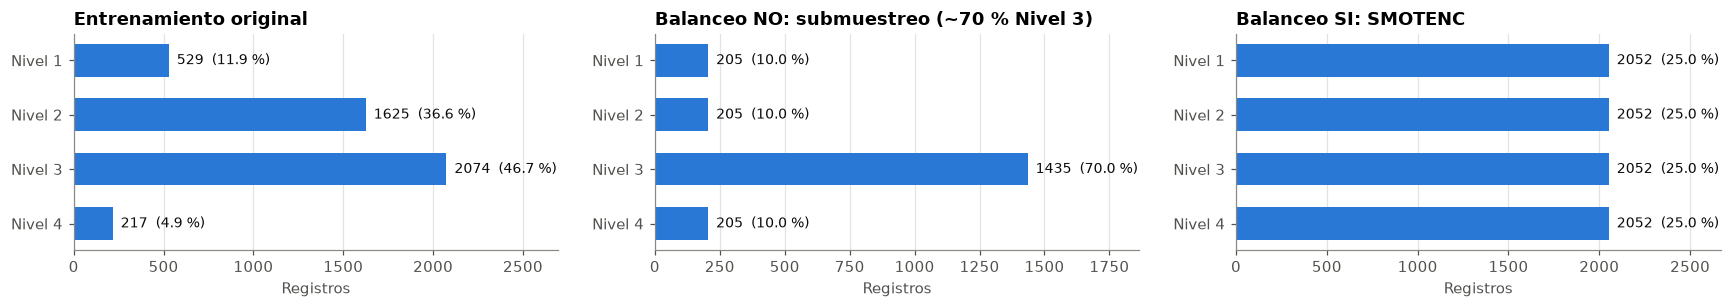

Reporte de outliers inyectados:


,Outliers previos,Outliers inyectados,Outliers totales,% outliers,Variables modificadas
3,55,54,109,5.02,"{'PUNT_SOCIALES_CIUDADANAS': 19, 'EDAD': 18, '..."
4,368,47,415,5.0,"{'PUNT_SOCIALES_CIUDADANAS': 16, 'EDAD': 15, '..."
7,55,54,109,5.02,"{'PUNT_SOCIALES_CIUDADANAS': 19, 'EDAD': 18, '..."
8,368,47,415,5.0,"{'PUNT_SOCIALES_CIUDADANAS': 16, 'EDAD': 15, '..."


In [84]:
# Distribución de clases resultante: desbalanceada vs. balanceada (sin outliers)
fig, axes = plt.subplots(1, 3, figsize=(16, 2.9))
graficar_distribucion_clases(y_train_0, "Entrenamiento original", ax=axes[0])
graficar_distribucion_clases(casos[1]["y_train"], "Balanceo NO: submuestreo (~70 % Nivel 3)", ax=axes[1])
graficar_distribucion_clases(casos[2]["y_train"], "Balanceo SI: SMOTENC", ax=axes[2])
plt.tight_layout()
plt.show()

print("Reporte de outliers inyectados:")
pd.DataFrame({k: casos[k]["reporte"] for k in (3, 4, 7, 8)}).T[
    ["Outliers previos", "Outliers inyectados", "Outliers totales", "% outliers", "Variables modificadas"]]

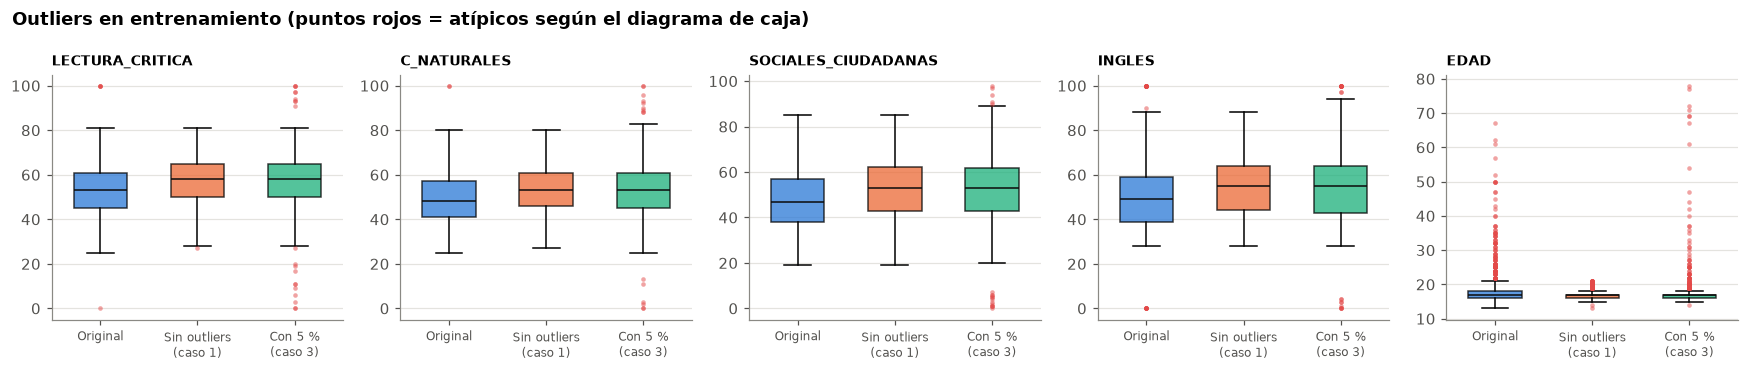

In [85]:
def graficar_outliers(versiones, columnas=VARIABLES_NUMERICAS):
    """Diagramas de caja de las numéricas en varias versiones del entrenamiento
    (sin escalar), para comparar el efecto de eliminar e inyectar outliers."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(3.2 * len(columnas), 3.4))
    for ax, col in zip(axes, columnas):
        datos = [v[col].values for v in versiones.values()]
        caja = ax.boxplot(datos, patch_artist=True, widths=0.55,
                          flierprops={"marker": "o", "markersize": 3, "alpha": 0.5,
                                      "markerfacecolor": "#e34948", "markeredgecolor": "none"},
                          medianprops={"color": "#0b0b0b"})
        for patch, color in zip(caja["boxes"], COLORES_SERIES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(versiones) + 1), list(versiones), fontsize=8)
        ax.set_title(col.replace("PUNT_", ""), fontsize=9, loc="left")
        ax.grid(axis="x", visible=False)
    fig.suptitle("Outliers en entrenamiento (puntos rojos = atípicos según el diagrama de caja)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


# Se comparan los casos 1 y 3: ambos sin escalar y con el MISMO balanceo (submuestreo),
# así la única diferencia entre ellos es el manejo de outliers. Los casos 2 y 4 pasan
# por SMOTE, que genera registros sintéticos y cambiaría la forma de las cajas.
graficar_outliers({"Original": X_train_base,
                   "Sin outliers\n(caso 1)": casos[1]["X_train"],
                   "Con 5 %\n(caso 3)": casos[3]["X_train"]})

### 4.9 Funciones para los demás bloques
- `obtener_datos_demo(caso)`: devuelve los mismos 3 registros de prueba para todas las técnicas (uno de Nivel 1, uno de Nivel 3 y uno de Nivel 4), de modo que las predicciones sean comparables entre técnicas. Así interpretamos la "evaluación de 3 datos de prueba" del enunciado.
- `obtener_datos_no_supervisado(caso)` (bloque 4): devuelve los registros de entrenamiento del caso, con el mismo CC, escalado y outliers, **sin la etiqueta**. La etiqueta se entrega aparte y solo se usa para la validación externa. Cada versión corresponde 1 a 1 con su caso de la Figura 1.

In [86]:
# Índices de los 3 registros de prueba de demostración (uno por clase extrema y uno central)
INDICES_DEMO = [y_test_0[y_test_0 == CLASES.index(c)].sample(1, random_state=SEMILLA).index[0]
                for c in ("Nivel 1", "Nivel 3", "Nivel 4")]


def obtener_datos_demo(numero, casos=casos):
    """Retorna (X, y) de los 3 registros de prueba de demostración en la versión del caso indicado."""
    c = casos[numero]
    return c["X_test"].loc[INDICES_DEMO], c["y_test"].loc[INDICES_DEMO]


def obtener_datos_no_supervisado(numero, casos=casos):
    """Bloque 4: retorna (X, etiqueta_externa) del caso indicado.
    X son los registros de entrenamiento del caso (mismo CC, escalado y outliers) sin la
    variable objetivo; la etiqueta se usa ÚNICAMENTE para la validación externa."""
    c = casos[numero]
    return c["X_train"].copy(), c["y_train"].map(dict(enumerate(CLASES)))


X_demo, y_demo = obtener_datos_demo(8)
print("Registros de demostración (caso 8):", [CLASES[v] for v in y_demo])
X_demo.iloc[:, :8]

Registros de demostración (caso 8): ['Nivel 1', 'Nivel 3', 'Nivel 4']


,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,EDAD,FAMI_EDUCACIONMADRE,FAMI_EDUCACIONPADRE,FAMI_ESTRATOVIVIENDA
3576,-1.192134,-1.319012,-1.520897,-1.459090,3.563987,-1.460099,-1.307686,-0.952237
397,0.752350,0.372907,1.213226,0.880354,-0.117091,-0.173036,-0.001627,-0.038230
4354,0.453198,0.961401,0.051224,0.880354,0.145844,-0.173036,-0.001627,0.875776


### 4.10 Registro de resultados (contrato común para los bloques 2, 3 y 4)
Centralizamos el cálculo de métricas en una sola función para que los 4 algoritmos se evalúen exactamente igual: mismo conjunto de prueba, mismas métricas, mismo promedio. Así la Figura 1 y las curvas ROC/PR de la sección 7 se construyen directamente con lo registrado, sin transcribir valores a mano.

- **`registrar_resultado(algoritmo, caso, modelo)`:** predice sobre la prueba del caso, calcula accuracy, precisión, recall y F1, y guarda las predicciones y las probabilidades. Acepta modelos de scikit-learn y de Keras.
- **Promedio `macro`:** cada clase pesa lo mismo. Con `weighted`, el buen desempeño en Nivel 3 (46.6 %) ocultaría los errores en Nivel 4 (4.9 %), que es justamente lo que el análisis de desbalance debe mostrar.
- **Probabilidades obligatorias:** son necesarias para las curvas ROC y Precision-Recall. Por eso SVM debe entrenarse con `probability=True`.
- **`registrar_clustering(tecnica, caso, X, etiquetas, modelo)`:** es el equivalente para el bloque 4. Calcula la inercia (K-Means) y el silhouette (en DBSCAN, sin los puntos de ruido) para la Figura 3.
- **Funciones de apoyo:**
  - `predecir_demo(...)`: los 3 datos de prueba.
  - `reporte_por_clase(...)` y `graficar_matriz_confusion(...)`: el reporte por clase y la matriz de confusión, para que tengan el mismo formato en todos los bloques.

In [87]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, silhouette_score)

ALGORITMOS = ["Árboles", "KNN", "SVM", "Redes Neuronales"]   # nombres exactos (columnas de la Figura 1)
METRICAS = ["Accuracy", "Precision", "Recall", "F1"]
TECNICAS_CLUSTERING = ["K-Means", "DBSCAN"]

RESULTADOS = {}              # (algoritmo, caso) -> métricas, predicciones y probabilidades
RESULTADOS_CLUSTERING = {}   # (tecnica, caso)   -> inercia, silhouette, clusters, ruido


def _es_keras(modelo):
    """True si el modelo es de Keras/TensorFlow."""
    return "keras" in type(modelo).__module__


def predecir_con_probabilidades(modelo, X):
    """Devuelve (y_pred, y_proba) para un modelo de scikit-learn o de Keras.
    - scikit-learn: y_pred = predict(X), y_proba = predict_proba(X).
    - Keras: y_proba = predict(X) (salida softmax), y_pred = clase de mayor probabilidad."""
    if _es_keras(modelo):
        y_proba = np.asarray(modelo.predict(np.asarray(X, dtype="float32"), verbose=0))
        return y_proba.argmax(axis=1), y_proba
    if not hasattr(modelo, "predict_proba"):
        raise ValueError("El modelo no tiene predict_proba. En SVM use SVC(probability=True, "
                         "random_state=SEMILLA); las probabilidades se necesitan para las curvas ROC/PR.")
    return np.asarray(modelo.predict(X)).astype(int), np.asarray(modelo.predict_proba(X))


def registrar_resultado(algoritmo, caso, modelo, parametros=None, casos=casos):
    """Evalúa `modelo` (ya entrenado) sobre el conjunto de PRUEBA del `caso` y guarda el resultado.

    algoritmo  : uno de ALGORITMOS ("Árboles", "KNN", "SVM", "Redes Neuronales").
    caso       : entero de 1 a 8 (fila de la Figura 1).
    modelo     : modelo de scikit-learn (con predict_proba) o de Keras (salida softmax de 4 neuronas).
    parametros : dict opcional con los hiperparámetros elegidos (se muestra en la tabla final).

    Calcula Accuracy y Precision/Recall/F1 con promedio macro. Si el par (algoritmo, caso)
    ya estaba registrado, lo reemplaza. Retorna el diccionario de métricas."""
    if algoritmo not in ALGORITMOS:
        raise ValueError(f"algoritmo debe ser uno de {ALGORITMOS}, no '{algoritmo}'")
    if caso not in casos:
        raise ValueError(f"caso debe estar entre 1 y 8, no {caso}")

    X_test, y_test = casos[caso]["X_test"], casos[caso]["y_test"].to_numpy()
    y_pred, y_proba = predecir_con_probabilidades(modelo, X_test)
    if y_proba.shape != (len(y_test), len(CLASES)):
        raise ValueError(f"Las probabilidades deben tener forma {(len(y_test), len(CLASES))}, "
                         f"no {y_proba.shape}. La salida debe tener una columna por clase.")

    metricas = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y_test, y_pred, average="macro", zero_division=0),
    }
    if (algoritmo, caso) in RESULTADOS:
        print(f"Aviso: se reemplaza el resultado previo de {algoritmo} en el caso {caso}.")
    RESULTADOS[(algoritmo, caso)] = {**metricas, "y_pred": y_pred, "y_proba": y_proba,
                                     "parametros": parametros or {}}
    print(f"{algoritmo} | caso {caso} | " + " | ".join(f"{m}: {v:.4f}" for m, v in metricas.items()))
    return metricas


def tabla_figura1(resultados=RESULTADOS, casos=casos):
    """Tabla de la Figura 1: una fila por caso y, por algoritmo, Accuracy/Precision/Recall/F1.
    Las celdas sin resultado registrado quedan vacías (NaN)."""
    filas = {}
    for k, c in casos.items():
        fila = {("Configuración", "Normalización"): c["normalizacion"],
                ("Configuración", "Outliers"): c["outliers"],
                ("Configuración", "Balanceo"): c["balanceo"]}
        for alg in ALGORITMOS:
            r = resultados.get((alg, k), {})
            for m in METRICAS:
                fila[(alg, m)] = round(r[m], 4) if m in r else np.nan
        filas[k] = fila
    tabla = pd.DataFrame(filas).T
    tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
    tabla.index.name = "Caso"
    return tabla


def reporte_por_clase(algoritmo, caso, casos=casos):
    """Reporte de precisión, recall y F1 por clase de un resultado registrado."""
    r = RESULTADOS[(algoritmo, caso)]
    reporte = classification_report(casos[caso]["y_test"], r["y_pred"], target_names=CLASES,
                                    output_dict=True, zero_division=0)
    return pd.DataFrame(reporte).T.round(4)


def graficar_matriz_confusion(algoritmo, caso, ax=None, casos=casos):
    """Matriz de confusión (conteos) de un resultado registrado, con los nombres de las clases."""
    r = RESULTADOS[(algoritmo, caso)]
    matriz = confusion_matrix(casos[caso]["y_test"], r["y_pred"], labels=range(len(CLASES)))
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 3.9))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1,
                linecolor="white", xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(f"{algoritmo} – caso {caso}", loc="left")
    ax.grid(False)
    return ax


def predecir_demo(algoritmo, caso, modelo):
    """Evaluación de los 3 datos de prueba de demostración (INDICES_DEMO): clase real,
    clase predicha y probabilidad de cada clase."""
    X_demo, y_demo = obtener_datos_demo(caso)
    y_pred, y_proba = predecir_con_probabilidades(modelo, X_demo)
    tabla = pd.DataFrame(y_proba.round(3), columns=[f"P({c})" for c in CLASES], index=X_demo.index)
    tabla.insert(0, "Predicho", [CLASES[p] for p in y_pred])
    tabla.insert(0, "Real", [CLASES[v] for v in y_demo])
    tabla.insert(0, "Técnica", f"{algoritmo} (caso {caso})")
    return tabla


def registrar_clustering(tecnica, caso, X, etiquetas, modelo=None, parametros=None):
    """Registra un agrupamiento para la Figura 3.

    tecnica   : "K-Means" o "DBSCAN".
    X         : los datos usados para agrupar (de obtener_datos_no_supervisado(caso)).
    etiquetas : etiqueta de cluster de cada registro (en DBSCAN, -1 = ruido).
    modelo    : el modelo ajustado (en K-Means se toma su inertia_).

    El silhouette excluye el ruido (-1) y requiere al menos 2 clusters; si no se cumple, queda NaN."""
    if tecnica not in TECNICAS_CLUSTERING:
        raise ValueError(f"tecnica debe ser una de {TECNICAS_CLUSTERING}, no '{tecnica}'")
    etiquetas = np.asarray(etiquetas)
    no_ruido = etiquetas != -1
    n_clusters = len(set(etiquetas[no_ruido]))
    silhouette = (silhouette_score(np.asarray(X)[no_ruido], etiquetas[no_ruido], random_state=SEMILLA)
                  if n_clusters >= 2 else np.nan)
    inercia = getattr(modelo, "inertia_", np.nan) if tecnica == "K-Means" else np.nan
    RESULTADOS_CLUSTERING[(tecnica, caso)] = {
        "Inertia": inercia, "Silhouette": silhouette, "Clusters": n_clusters,
        "Ruido": int((~no_ruido).sum()), "parametros": parametros or {}}
    print(f"{tecnica} | caso {caso} | clusters: {n_clusters} | ruido: {int((~no_ruido).sum())} | "
          f"inercia: {inercia:.2f} | silhouette: {silhouette:.4f}")
    return RESULTADOS_CLUSTERING[(tecnica, caso)]


def tabla_figura3(casos=casos):
    """Tabla de la Figura 3: inercia y silhouette de K-Means y silhouette de DBSCAN por caso."""
    filas = {}
    for k, c in casos.items():
        km = RESULTADOS_CLUSTERING.get(("K-Means", k), {})
        db = RESULTADOS_CLUSTERING.get(("DBSCAN", k), {})
        filas[k] = {"Normalización": c["normalizacion"], "Outliers": c["outliers"],
                    "Balanceo": c["balanceo"],
                    "K-Means Inertia": km.get("Inertia", np.nan),
                    "K-Means Silhouette": km.get("Silhouette", np.nan),
                    "DBSCAN Silhouette": db.get("Silhouette", np.nan)}
    tabla = pd.DataFrame(filas).T
    tabla.index.name = "Caso"
    return tabla


print(f"Contrato listo. Algoritmos: {ALGORITMOS} | Técnicas de clustering: {TECNICAS_CLUSTERING}")
print(f"Resultados registrados: {len(RESULTADOS)} supervisados, {len(RESULTADOS_CLUSTERING)} de clustering")

Contrato listo. Algoritmos: ['Árboles', 'KNN', 'SVM', 'Redes Neuronales'] | Técnicas de clustering: ['K-Means', 'DBSCAN']
Resultados registrados: 0 supervisados, 0 de clustering


## 5. Árboles de decisión y KNN (bloque 2)
*Sección en desarrollo.*

## 6. SVM y redes neuronales (bloque 3)
Entrenamos SVM y redes neuronales en los 8 casos de la Figura 1 con dos criterios comunes:
- **Los hiperparámetros se eligen con el F1 macro de validación**, la misma métrica que reporta la Figura 1. La prueba solo se usa a través de `registrar_resultado` y `predecir_demo`.
- **No usamos `class_weight`.** Si lo usáramos, el efecto del balanceo se mezclaría con el de la versión del dataset, y la Figura 1 dejaría de aislar el efecto del preprocesamiento.

La sección tarda ~6 minutos en total: ~2 minutos SVM y ~4 minutos las redes.

### 6.1 Máquinas de vectores de soporte (SVM)
#### 6.1.1 Búsqueda de kernel, C y gamma
Evaluamos 15 configuraciones por caso sobre validación: lineal (C ∈ {0.01, 0.1, 1}), RBF (C ∈ {0.1, 1, 10} × gamma ∈ {scale, 0.01, 0.1}) y polinómico de grado 2 (C ∈ {0.1, 1, 10}).
- **Buscamos por caso y no con una configuración fija.** El efecto de C y gamma depende de la escala de cada versión: con una configuración fija, los casos sin escalar perderían por la elección del hiperparámetro y no por el preprocesamiento.
- **Grado 2 en el polinómico:** evalúa interacciones entre pares de variables sin sumar más configuraciones a una búsqueda que se repite en 8 casos.
- **La búsqueda entrena sin probabilidades.** `probability=True` calibra con una validación cruzada interna de 5 folds y multiplica el costo por ~5, así que solo lo activamos en el modelo final de cada caso.
- En empate de F1 preferimos el C más pequeño, que es el modelo más regularizado.

In [29]:
# ============================================================
# 6.1 SVM: búsqueda de hiperparámetros con el conjunto de validación
# ============================================================
import time
from joblib import Parallel, delayed
from sklearn.svm import SVC

# Rejilla de búsqueda (15 combinaciones por caso). En el lineal no incluimos C = 10: en los casos
# sin escalar no converge en un tiempo razonable y en ningún caso escalado fue el mejor.
REJILLA_SVM = (
    [{"kernel": "linear", "C": C} for C in (0.01, 0.1, 1)]
    + [{"kernel": "rbf", "C": C, "gamma": g} for C in (0.1, 1, 10) for g in ("scale", 0.01, 0.1)]
    + [{"kernel": "poly", "degree": 2, "C": C, "gamma": "scale"} for C in (0.1, 1, 10)]
)


def evaluar_config_svm(caso, config):
    """Entrena un SVC con `config` sobre el entrenamiento del caso y retorna el F1 macro
    y el accuracy sobre VALIDACIÓN. Sin probabilidades para que la búsqueda sea rápida."""
    d = casos[caso]
    modelo = SVC(**config, random_state=SEMILLA).fit(d["X_train"], d["y_train"])
    y_pred = modelo.predict(d["X_val"])
    return (f1_score(d["y_val"], y_pred, average="macro"),
            accuracy_score(d["y_val"], y_pred))


def buscar_svm(caso, rejilla=REJILLA_SVM):
    """Evalúa todas las configuraciones de la rejilla en el caso indicado.
    Retorna un DataFrame ordenado por F1 macro de validación (la primera fila es la elegida).
    En empate de F1 se prefiere el C más pequeño (margen más amplio, modelo más simple)."""
    metricas = Parallel(n_jobs=-1)(delayed(evaluar_config_svm)(caso, c) for c in rejilla)
    filas = [{"caso": caso, "kernel": c["kernel"], "C": c["C"], "gamma": c.get("gamma", "-"),
              "config": c, "F1 val": f1_val, "Accuracy val": acc_val}
             for c, (f1_val, acc_val) in zip(rejilla, metricas)]
    tabla = pd.DataFrame(filas)
    return tabla.sort_values(["F1 val", "C"], ascending=[False, True]).reset_index(drop=True)


def entrenar_svm_final(caso, config):
    """Entrena el SVC final del caso con probability=True (necesario para ROC/PR)."""
    d = casos[caso]
    return SVC(**config, probability=True, random_state=SEMILLA).fit(d["X_train"], d["y_train"])


# Búsqueda, entrenamiento final y registro en los 8 casos
inicio_svm = time.time()
BUSQUEDA_SVM = {}   # caso -> tabla de la búsqueda
MODELOS_SVM = {}    # caso -> SVC final
for k in casos:
    BUSQUEDA_SVM[k] = buscar_svm(k)
    config_k = BUSQUEDA_SVM[k].loc[0, "config"]
    MODELOS_SVM[k] = entrenar_svm_final(k, config_k)
    registrar_resultado("SVM", k, MODELOS_SVM[k], config_k)
print(f"\nTiempo SVM (búsqueda + entrenamiento de los 8 casos): {time.time() - inicio_svm:.0f} s")

SVM | caso 1 | Accuracy: 0.5897 | Precision: 0.5835 | Recall: 0.5792 | F1: 0.5186


SVM | caso 2 | Accuracy: 0.6432 | Precision: 0.5742 | Recall: 0.7010 | F1: 0.6052


SVM | caso 3 | Accuracy: 0.5887 | Precision: 0.6009 | Recall: 0.5636 | F1: 0.5160


SVM | caso 4 | Accuracy: 0.6453 | Precision: 0.5666 | Recall: 0.6645 | F1: 0.5949


SVM | caso 5 | Accuracy: 0.5876 | Precision: 0.5820 | Recall: 0.5718 | F1: 0.5148


SVM | caso 6 | Accuracy: 0.6390 | Precision: 0.5506 | Recall: 0.6131 | F1: 0.5717


SVM | caso 7 | Accuracy: 0.5866 | Precision: 0.6005 | Recall: 0.5622 | F1: 0.5135


SVM | caso 8 | Accuracy: 0.6443 | Precision: 0.5660 | Recall: 0.6654 | F1: 0.5944

Tiempo SVM (búsqueda + entrenamiento de los 8 casos): 119 s


In [30]:
def resumen_eleccion_svm(busqueda=BUSQUEDA_SVM):
    """Tabla con la configuración elegida por caso, su F1 en validación y el mejor F1
    de validación de cada kernel (para justificar la elección del kernel)."""
    filas = []
    for k, tabla in busqueda.items():
        mejor = tabla.iloc[0]
        fila = {"Caso": k, "ED": casos[k]["normalizacion"][-3:-1], "Outliers": casos[k]["outliers"],
                "Balanceo": casos[k]["balanceo"], "Kernel": mejor["kernel"], "C": mejor["C"],
                "gamma": mejor["gamma"], "F1 val": round(mejor["F1 val"], 4)}
        for kern in ("linear", "rbf", "poly"):
            fila[f"Mejor F1 val {kern}"] = round(tabla.loc[tabla["kernel"] == kern, "F1 val"].max(), 4)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Caso")


display(resumen_eleccion_svm())

,ED,Outliers,Balanceo,Kernel,C,gamma,F1 val,Mejor F1 val linear,Mejor F1 val rbf,Mejor F1 val poly
Caso,,,,,,,,,,
1,NO,NO,NO,linear,1.0,-,0.5189,0.5189,0.4846,0.4772
2,NO,NO,SI,rbf,10.0,scale,0.6059,0.5989,0.6059,0.5942
3,NO,SI,NO,linear,1.0,-,0.5355,0.5355,0.4926,0.4726
4,NO,SI,SI,linear,0.1,-,0.6138,0.6138,0.6084,0.5940
5,SI,NO,NO,linear,1.0,-,0.5201,0.5201,0.5173,0.5024
6,SI,NO,SI,poly,1.0,scale,0.5992,0.5957,0.5931,0.5992
7,SI,SI,NO,linear,1.0,-,0.5379,0.5379,0.5237,0.5131
8,SI,SI,SI,linear,0.1,-,0.6112,0.6112,0.6048,0.6091


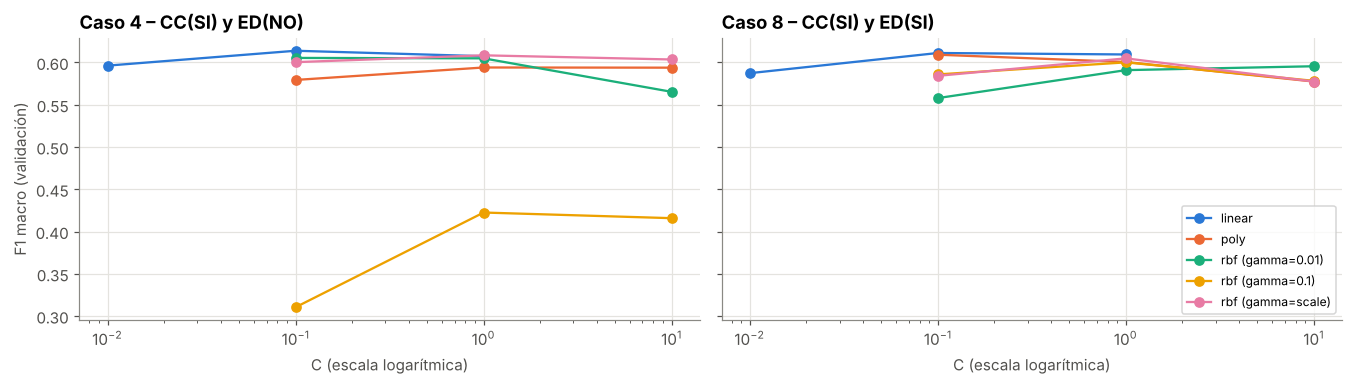

Caso 4:


,kernel,C,gamma,F1 val,Accuracy val
0,linear,0.10,-,0.6138,0.6481
1,rbf,1.00,scale,0.6084,0.6429
2,linear,1.00,-,0.6074,0.6418
3,rbf,0.10,0.01,0.6054,0.6471
4,rbf,1.00,0.01,0.6049,0.6565
5,rbf,10.00,scale,0.6035,0.6397
6,rbf,0.10,scale,0.6004,0.6261
7,linear,0.01,-,0.5963,0.6313
8,poly,1.00,scale,0.5940,0.6271
9,poly,10.00,scale,0.5938,0.6282


Caso 8:


,kernel,C,gamma,F1 val,Accuracy val
0,linear,0.10,-,0.6112,0.6481
1,linear,1.00,-,0.6095,0.6429
2,poly,0.10,scale,0.6091,0.6502
3,rbf,1.00,scale,0.6048,0.6523
4,poly,1.00,scale,0.6006,0.6502
5,rbf,1.00,0.1,0.6001,0.6534
6,rbf,10.00,0.01,0.5955,0.6439
7,rbf,1.00,0.01,0.5909,0.6292
8,linear,0.01,-,0.5873,0.6239
9,rbf,0.10,0.1,0.5859,0.6218


In [31]:
def graficar_busqueda_svm(casos_graf=(4, 8), busqueda=BUSQUEDA_SVM):
    """F1 macro de validación de cada configuración de la rejilla, por kernel y C,
    para comparar los casos indicados (por defecto, el caso 4 sin escalar y el 8 escalado)."""
    fig, axes = plt.subplots(1, len(casos_graf), figsize=(6.2 * len(casos_graf), 3.6), sharey=True)
    for ax, k in zip(np.atleast_1d(axes), casos_graf):
        tabla = busqueda[k].copy()
        tabla["serie"] = tabla.apply(lambda r: r["kernel"] if r["kernel"] != "rbf"
                                     else f"rbf (gamma={r['gamma']})", axis=1)
        for i, (serie, grupo) in enumerate(tabla.groupby("serie", sort=True)):
            grupo = grupo.sort_values("C")
            ax.plot(grupo["C"], grupo["F1 val"], marker="o", color=COLORES_SERIES[i], label=serie)
        ax.set_xscale("log")
        ax.set_xlabel("C (escala logarítmica)")
        ax.set_title(f"Caso {k} – {casos[k]['normalizacion']}", loc="left")
    np.atleast_1d(axes)[0].set_ylabel("F1 macro (validación)")
    np.atleast_1d(axes)[-1].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


graficar_busqueda_svm()
for k in (4, 8):
    print(f"Caso {k}:")
    display(BUSQUEDA_SVM[k][["kernel", "C", "gamma", "F1 val", "Accuracy val"]].round(4))

#### 6.1.2 Justificación de kernel, C y gamma
**Kernel.** El lineal es el mejor en 6 de los 8 casos. Donde gana otro kernel, la ventaja es menor de 0.01 de F1 (RBF en el caso 2: 0.6059 frente a 0.5989; polinómico en el caso 6: 0.5992 frente a 0.5957). En cambio, en los casos desbalanceados sin escalar el lineal supera al mejor RBF por 0.034 (caso 1) y 0.043 (caso 3). Interpretamos que la frontera entre niveles es casi lineal: los puntajes de las otras áreas están muy correlacionados con el de matemáticas (ρ 0.69–0.82, sección 3.5) y el objetivo es ordinal.

**C.** En los 4 casos desbalanceados el mejor C es 1; en los casos balanceados con outliers (4 y 8) baja a 0.1. En esos casos el margen más amplio da mejor validación. Nuestra interpretación es que tolera mejor los registros sintéticos de SMOTENC y los outliers inyectados.

**gamma (solo RBF).** Es el hiperparámetro más sensible a la escala. Con gamma = 0.1, el F1 de validación cae a 0.31–0.42 en el caso 4 (sin escalar), frente a 0.58–0.60 en el caso 8 (escalado), porque sin escalar las distancias quedan dominadas por `EDAD` y los puntajes. `gamma="scale"` compensa en parte, ya que se ajusta a la varianza de los datos.

**Por qué el escalado casi no cambia el F1 final del SVM:** la búsqueda por caso elige configuraciones poco sensibles a la escala (lineal o `gamma="scale"`). Con un gamma fijo, la diferencia sí aparece, como muestra la gráfica.

#### 6.1.3 Regiones de decisión (PCA a 2D)
PCA se ajusta con el entrenamiento del caso y solo se usa para visualizar. Para graficar entrenamos un SVM aparte sobre los 2 componentes, con la misma configuración elegida; el modelo registrado se entrena con las 65 columnas. Comparamos el caso 4 (sin escalar) con el 8 (escalado), que tienen los mismos registros.

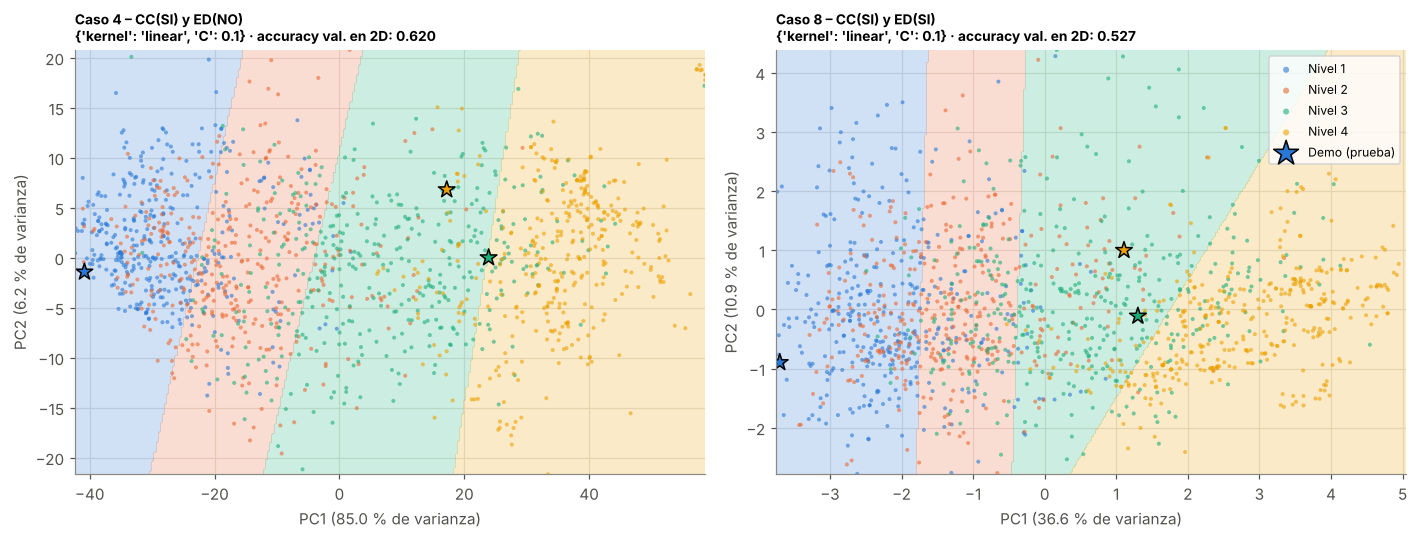

Caso 4 | varianza PC1+PC2: 91.3 % | variables con más peso en PC1: ['PUNT_INGLES', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_C_NATURALES']
Caso 8 | varianza PC1+PC2: 47.4 % | variables con más peso en PC1: ['PUNT_C_NATURALES', 'PUNT_INGLES', 'PUNT_SOCIALES_CIUDADANAS']


In [32]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap


def regiones_decision_svm(caso, config, ax, n_puntos=1500, resolucion=300):
    """Regiones de decisión de un SVM en el plano de las 2 primeras componentes principales.

    PCA se ajusta con el entrenamiento del caso y se usa SOLO para visualizar: el SVM
    graficado es un modelo aparte entrenado sobre los 2 componentes con la misma
    configuración que el modelo registrado (que se entrena con las 65 columnas).
    Se dibuja una muestra de `n_puntos` registros de entrenamiento y los 3 de demostración."""
    d = casos[caso]
    pca = PCA(n_components=2, random_state=SEMILLA).fit(d["X_train"])
    Z_train = pca.transform(d["X_train"])
    svm_2d = SVC(**config, random_state=SEMILLA).fit(Z_train, d["y_train"])

    # Malla sobre el rango de los datos
    x_min, x_max = np.percentile(Z_train[:, 0], [0.5, 99.5])
    y_min, y_max = np.percentile(Z_train[:, 1], [0.5, 99.5])
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolucion), np.linspace(y_min, y_max, resolucion))
    regiones = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cmap = ListedColormap([COLORES_CLASES[c] for c in CLASES])
    ax.contourf(xx, yy, regiones, levels=np.arange(-0.5, len(CLASES)), cmap=cmap, alpha=0.22)

    # Muestra de puntos de entrenamiento
    rng = np.random.default_rng(SEMILLA)
    idx = rng.choice(len(Z_train), size=min(n_puntos, len(Z_train)), replace=False)
    for i, clase in enumerate(CLASES):
        sel = idx[d["y_train"].to_numpy()[idx] == i]
        ax.scatter(Z_train[sel, 0], Z_train[sel, 1], s=7, color=COLORES_CLASES[clase],
                   alpha=0.6, label=clase, edgecolors="none")

    # Los 3 registros de demostración (prueba)
    X_demo_k, y_demo_k = obtener_datos_demo(caso)
    Z_demo = pca.transform(X_demo_k)
    ax.scatter(Z_demo[:, 0], Z_demo[:, 1], s=130, marker="*", c=[COLORES_CLASES[CLASES[v]] for v in y_demo_k],
               edgecolors="black", linewidths=1, label="Demo (prueba)")

    var = pca.explained_variance_ratio_ * 100
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel(f"PC1 ({var[0]:.1f} % de varianza)")
    ax.set_ylabel(f"PC2 ({var[1]:.1f} % de varianza)")
    exactitud_2d = accuracy_score(d["y_val"], svm_2d.predict(pca.transform(d["X_val"])))
    ax.set_title(f"Caso {caso} – {casos[caso]['normalizacion']}\n"
                 f"{config} · accuracy val. en 2D: {exactitud_2d:.3f}", loc="left", fontsize=9)
    return pca


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
PCA_SVM = {k: regiones_decision_svm(k, BUSQUEDA_SVM[k].loc[0, "config"], ax)
           for k, ax in zip((4, 8), axes)}
axes[1].legend(fontsize=8, loc="upper right", markerscale=1.5)
plt.tight_layout()
plt.show()

for k, pca in PCA_SVM.items():
    cargas = pd.Series(pca.components_[0], index=casos[k]["X_train"].columns)
    print(f"Caso {k} | varianza PC1+PC2: {pca.explained_variance_ratio_.sum() * 100:.1f} % | "
          f"variables con más peso en PC1: {cargas.abs().nlargest(3).index.tolist()}")

- **Las regiones son franjas ordenadas de Nivel 1 a Nivel 4 a lo largo de PC1**, que es una combinación de los puntajes de lectura, ciencias, sociales e inglés. Esto concuerda con la elección del kernel lineal y con el carácter ordinal del objetivo.
- **Los niveles vecinos se solapan.** Por eso los errores se concentran entre clases adyacentes: en la matriz de confusión del caso 8 (sección 6.1.5), solo 14 de los 339 errores saltan más de un nivel.
- **Efecto del escalado en PCA:** sin escalar, PC1 explica el 85.0 % de la varianza porque los puntajes (0–100) dominan sobre las dummies (0/1). Con escalado, PC1 y PC2 explican juntas el 47.4 % y el resto de variables gana peso.
- El accuracy de validación del SVM en 2D (0.620 en el caso 4 y 0.527 en el 8) es mayor sin escalar solo porque ahí PC1 resume casi todos los puntajes. Esta cifra describe la visualización, no el modelo registrado.

#### 6.1.4 Evaluación de los 3 datos de prueba

In [33]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("SVM", k, MODELOS_SVM[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,SVM (caso 1),Nivel 1,Nivel 1,0.720,0.266,0.013,0.000
397,SVM (caso 1),Nivel 3,Nivel 3,0.002,0.018,0.948,0.032
4354,SVM (caso 1),Nivel 4,Nivel 3,0.000,0.006,0.932,0.061
3576,SVM (caso 2),Nivel 1,Nivel 1,0.971,0.029,0.001,0.000
397,SVM (caso 2),Nivel 3,Nivel 3,0.001,0.017,0.906,0.075
4354,SVM (caso 2),Nivel 4,Nivel 3,0.001,0.012,0.751,0.236
3576,SVM (caso 3),Nivel 1,Nivel 1,0.566,0.412,0.022,0.000
397,SVM (caso 3),Nivel 3,Nivel 3,0.001,0.042,0.875,0.082
4354,SVM (caso 3),Nivel 4,Nivel 3,0.002,0.011,0.911,0.076
3576,SVM (caso 4),Nivel 1,Nivel 1,0.842,0.156,0.001,0.000


- Los registros de Nivel 1 y Nivel 3 se clasifican bien en 7 de los 8 casos. La excepción es el caso 6, que asigna Nivel 2 al registro de Nivel 1.
- El registro de Nivel 4 se predice como Nivel 3 en los 8 casos. Aun así, el balanceo sube su probabilidad de Nivel 4: de 0.054–0.076 en los casos desbalanceados a 0.207–0.236 en los casos 2, 4 y 8.

#### 6.1.5 Caso 8: matriz de confusión y reporte por clase

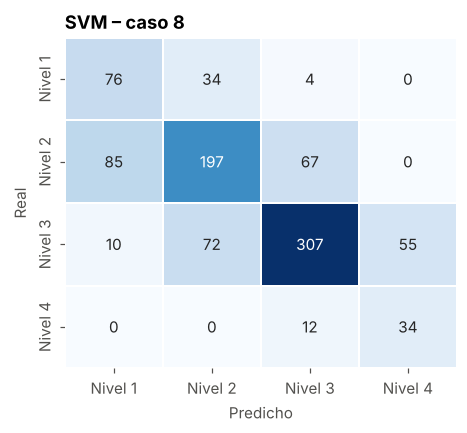

,precision,recall,f1-score,support
Nivel 1,0.4444,0.6667,0.5333,114.0000
Nivel 2,0.6502,0.5645,0.6043,349.0000
Nivel 3,0.7872,0.6914,0.7362,444.0000
Nivel 4,0.3820,0.7391,0.5037,46.0000
accuracy,0.6443,0.6443,0.6443,0.6443
macro avg,0.5660,0.6654,0.5944,953.0000
weighted avg,0.6764,0.6443,0.6524,953.0000


In [34]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("SVM", 8, ax=ax)
plt.show()
display(reporte_por_clase("SVM", 8))

- **Nivel 4:** el recall es alto (0.739) pero la precisión es baja (0.382). El modelo detecta 34 de los 46 estudiantes de Nivel 4, a cambio de asignar Nivel 4 a 55 estudiantes de Nivel 3.
- **Nivel 1:** el recall es 0.667 y la precisión 0.444. Detecta 76 de los 114 estudiantes en riesgo, y la mayoría de sus falsas alarmas (85) son estudiantes de Nivel 2, el nivel vecino.
- Con accuracy de 0.644 y F1 macro de 0.594, el SVM sacrifica precisión en las clases extremas para ganar recall. En un uso de alerta temprana, una falsa alarma en Nivel 2 cuesta menos que no detectar a un estudiante de Nivel 1.

### 6.2 Redes neuronales
#### 6.2.1 Arquitectura y configuración
- **Capas ocultas densas con ReLU** y salida `Dense(4, softmax)` en el orden de `CLASES`, con pérdida `sparse_categorical_crossentropy` porque las etiquetas son enteros 0–3.
- **Regularización en todos los casos:**
  - Dropout después de cada capa oculta.
  - Penalización L2 en los pesos de las capas ocultas.
  - BatchNormalization después de cada capa oculta.
- **Callbacks:**
  - EarlyStopping sobre la pérdida de validación (paciencia 15), restaurando los mejores pesos.
  - ReduceLROnPlateau, que divide la tasa de aprendizaje entre 2 tras 5 épocas sin mejora (mínimo 1e-5).
  - No usamos ModelCheckpoint: `restore_best_weights` ya conserva en memoria los pesos de la mejor época, y guardar archivos no cambiaría el resultado.
- **Optimización:** Adam (tasa inicial 1e-3), lotes de 64 y hasta 200 épocas. Monitoreamos la pérdida y no el accuracy porque es continua y reacciona antes al sobreajuste.
- **La misma arquitectura en los 8 casos.** Así las diferencias de la Figura 1 se pueden atribuir al preprocesamiento. La elegimos en el caso 8, que tiene todo el preprocesamiento aplicado.
- **Reproducibilidad:** `fijar_semillas()` antes de construir cada red, la semilla en el Dropout y `enable_op_determinism()`. Dos ejecuciones dan las mismas cifras.

In [35]:
# ============================================================
# 6.2 Redes neuronales: construcción y entrenamiento
# ============================================================
import tensorflow as tf

tf.config.experimental.enable_op_determinism()   # mismas cifras en cada ejecución (CPU)
tf.get_logger().setLevel("ERROR")


def construir_red(n_entradas, capas=(128, 64), dropout=0.3, l2=1e-4, batch_norm=True, lr=1e-3):
    """Red densa para clasificación en 4 clases.

    capas      : neuronas de cada capa oculta (activación ReLU).
    dropout    : tasa de Dropout después de cada capa oculta (0 = sin Dropout).
    l2         : penalización L2 de los pesos de las capas ocultas (0 = sin L2).
    batch_norm : BatchNormalization después de cada capa oculta.
    Salida Dense(4, softmax) en el orden de CLASES; pérdida sparse_categorical_crossentropy
    porque las etiquetas son enteros 0–3."""
    fijar_semillas()   # misma inicialización de pesos para cada red
    regularizador = tf.keras.regularizers.l2(l2) if l2 else None
    modelo = tf.keras.Sequential([tf.keras.layers.Input(shape=(n_entradas,))])
    for neuronas in capas:
        modelo.add(tf.keras.layers.Dense(neuronas, activation="relu", kernel_regularizer=regularizador))
        if batch_norm:
            modelo.add(tf.keras.layers.BatchNormalization())
        if dropout:
            modelo.add(tf.keras.layers.Dropout(dropout, seed=SEMILLA))
    modelo.add(tf.keras.layers.Dense(len(CLASES), activation="softmax"))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def callbacks_red(paciencia_parada=15, paciencia_lr=5):
    """Callbacks de entrenamiento:
    - EarlyStopping sobre la pérdida de validación, restaurando los mejores pesos.
    - ReduceLROnPlateau: divide la tasa de aprendizaje entre 2 si la pérdida de validación se estanca."""
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia_parada,
                                             restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                 patience=paciencia_lr, min_lr=1e-5)]


def entrenar_red(caso, config, epocas=200, tamano_lote=64, usar_callbacks=True):
    """Construye y entrena la red del caso con la configuración `config`
    (argumentos de construir_red). La validación se usa como validation_data
    (callbacks y curvas). Retorna (modelo, historia, F1 macro en validación)."""
    d = casos[caso]
    X_tr, X_va = d["X_train"].to_numpy("float32"), d["X_val"].to_numpy("float32")
    modelo = construir_red(X_tr.shape[1], **config)
    historia = modelo.fit(X_tr, d["y_train"].to_numpy(), validation_data=(X_va, d["y_val"].to_numpy()),
                          epochs=epocas, batch_size=tamano_lote, verbose=0, shuffle=True,
                          callbacks=callbacks_red() if usar_callbacks else [])
    y_pred_val = modelo.predict(X_va, verbose=0).argmax(axis=1)
    return modelo, historia, f1_score(d["y_val"], y_pred_val, average="macro")

#### 6.2.2 Proceso de configuración
Comparamos 4 arquitecturas regularizadas y una sin regularización (misma arquitectura que C, pero sin Dropout, L2 ni BatchNormalization).

In [36]:
# Proceso de configuración: comparamos arquitecturas y regularización en el caso 8
# (todo el preprocesamiento aplicado) con el F1 macro de validación.
CONFIGS_RED = {
    "A: [32] · drop 0.2 · L2 1e-4":           {"capas": (32,), "dropout": 0.2, "l2": 1e-4},
    "B: [64, 32] · drop 0.3 · L2 1e-4":       {"capas": (64, 32), "dropout": 0.3, "l2": 1e-4},
    "C: [128, 64] · drop 0.3 · L2 1e-4":      {"capas": (128, 64), "dropout": 0.3, "l2": 1e-4},
    "D: [128, 64, 32] · drop 0.4 · L2 1e-3":  {"capas": (128, 64, 32), "dropout": 0.4, "l2": 1e-3},
    "E: [128, 64] · sin regularización":      {"capas": (128, 64), "dropout": 0.0, "l2": 0.0,
                                               "batch_norm": False},
}


def comparar_configs_red(caso=8, configs=CONFIGS_RED):
    """Entrena cada configuración en el caso indicado y retorna (tabla, historias).
    La tabla tiene el F1 macro de validación, la época con menor pérdida de validación y
    la brecha entre la pérdida de validación y la de entrenamiento en esa época."""
    filas, historias = [], {}
    for nombre, config in configs.items():
        _, historia, f1_val = entrenar_red(caso, config)
        h = historia.history
        mejor = int(np.argmin(h["val_loss"]))
        filas.append({"Configuración": nombre, "F1 val": round(f1_val, 4),
                      "Accuracy val": round(h["val_accuracy"][mejor], 4),
                      "Mejor época": mejor + 1, "Épocas entrenadas": len(h["loss"]),
                      "Pérdida val": round(h["val_loss"][mejor], 4),
                      "Brecha val-train": round(h["val_loss"][mejor] - h["loss"][mejor], 4)})
        historias[nombre] = h
    return pd.DataFrame(filas).set_index("Configuración"), historias


inicio_cfg = time.time()
TABLA_CONFIGS_RED, HISTORIAS_CONFIGS_RED = comparar_configs_red()
display(TABLA_CONFIGS_RED)
print(f"Tiempo de la comparación: {time.time() - inicio_cfg:.0f} s")

,F1 val,Accuracy val,Mejor época,Épocas entrenadas,Pérdida val,Brecha val-train
Configuración,,,,,,
A: [32] · drop 0.2 · L2 1e-4,0.6190,0.6660,17,32,0.7572,0.1792
"B: [64, 32] · drop 0.3 · L2 1e-4",0.6049,0.6555,12,27,0.7724,0.1573
"C: [128, 64] · drop 0.3 · L2 1e-4",0.6152,0.6513,10,25,0.7816,0.1926
"D: [128, 64, 32] · drop 0.4 · L2 1e-3",0.6238,0.6702,18,33,0.8251,0.1329
"E: [128, 64] · sin regularización",0.6085,0.6460,5,20,0.7870,0.2616


Tiempo de la comparación: 58 s


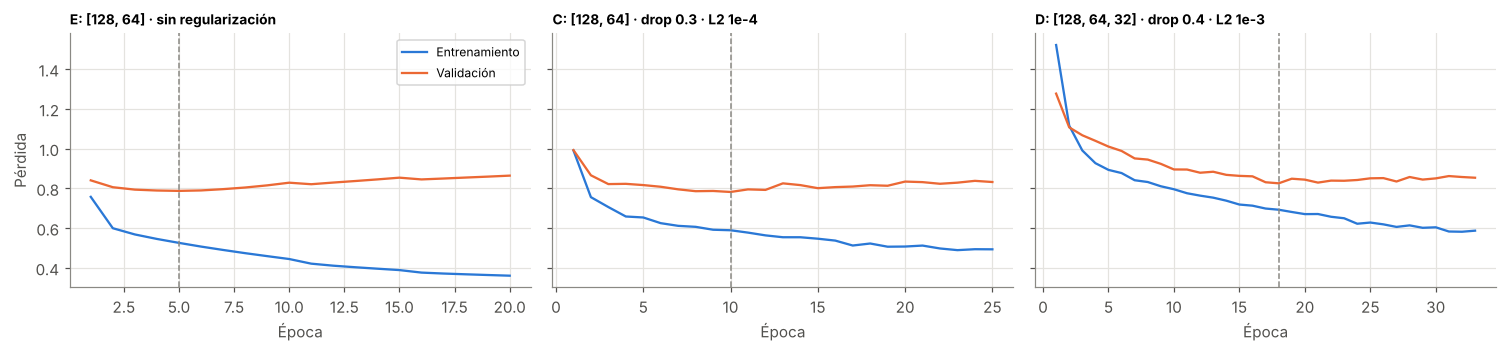

In [37]:
def graficar_curvas_configs(historias, nombres):
    """Pérdida de entrenamiento y de validación por época de las configuraciones indicadas."""
    fig, axes = plt.subplots(1, len(nombres), figsize=(4.6 * len(nombres), 3.3), sharey=True)
    for ax, nombre in zip(axes, nombres):
        h = historias[nombre]
        epocas = np.arange(1, len(h["loss"]) + 1)
        ax.plot(epocas, h["loss"], color=COLORES_SERIES[0], label="Entrenamiento")
        ax.plot(epocas, h["val_loss"], color=COLORES_SERIES[1], label="Validación")
        mejor = int(np.argmin(h["val_loss"])) + 1
        ax.axvline(mejor, color="#8a8984", linestyle="--", linewidth=1)
        ax.set_title(nombre, loc="left", fontsize=9)
        ax.set_xlabel("Época")
    axes[0].set_ylabel("Pérdida")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


graficar_curvas_configs(HISTORIAS_CONFIGS_RED, ["E: [128, 64] · sin regularización",
                                                "C: [128, 64] · drop 0.3 · L2 1e-4",
                                                "D: [128, 64, 32] · drop 0.4 · L2 1e-3"])

**Elegimos la configuración D** (`[128, 64, 32]`, Dropout 0.4, L2 1e-3): tiene el mayor F1 de validación (0.6238) y la menor brecha entre la pérdida de validación y la de entrenamiento (0.1329).
- **La regularización es necesaria.** Sin ella (E), la pérdida de validación toca su mínimo en la época 5 y luego sube mientras la de entrenamiento sigue bajando: la brecha llega a 0.2616. La misma arquitectura regularizada (C) retrasa el mínimo a la época 10 y reduce la brecha a 0.1926. D, con más Dropout y L2, lo retrasa a la época 18.
- **El tamaño de la red pesa poco.** Las cuatro configuraciones regularizadas quedan entre 0.6049 y 0.6238 de F1, así que no atribuimos la elección a la capacidad de la red, sino a su menor sobreajuste.
- La columna "Pérdida val" incluye la penalización L2, por lo que no es comparable entre configuraciones con distinto L2; para comparar el sobreajuste usamos la brecha.

#### 6.2.3 Entrenamiento en los 8 casos

In [38]:
# Arquitectura final (configuración D) en los 8 casos
CONFIG_RED_FINAL = CONFIGS_RED["D: [128, 64, 32] · drop 0.4 · L2 1e-3"]

inicio_red = time.time()
MODELOS_RED, HISTORIAS_RED = {}, {}
for k in casos:
    MODELOS_RED[k], historia_k, _ = entrenar_red(k, CONFIG_RED_FINAL)
    HISTORIAS_RED[k] = historia_k.history
    registrar_resultado("Redes Neuronales", k, MODELOS_RED[k],
                        {**CONFIG_RED_FINAL, "batch_norm": True, "épocas": len(historia_k.history["loss"])})
print(f"\nTiempo redes (8 casos): {time.time() - inicio_red:.0f} s")

Redes Neuronales | caso 1 | Accuracy: 0.5866 | Precision: 0.6422 | Recall: 0.5843 | F1: 0.5055


Redes Neuronales | caso 2 | Accuracy: 0.6905 | Precision: 0.6397 | Recall: 0.6463 | F1: 0.6385


Redes Neuronales | caso 3 | Accuracy: 0.5908 | Precision: 0.6306 | Recall: 0.5558 | F1: 0.4980


Redes Neuronales | caso 4 | Accuracy: 0.6705 | Precision: 0.6491 | Recall: 0.6422 | F1: 0.6378


Redes Neuronales | caso 5 | Accuracy: 0.5960 | Precision: 0.6098 | Recall: 0.5781 | F1: 0.5269


Redes Neuronales | caso 6 | Accuracy: 0.6380 | Precision: 0.5534 | Recall: 0.6221 | F1: 0.5739


Redes Neuronales | caso 7 | Accuracy: 0.6055 | Precision: 0.6341 | Recall: 0.5712 | F1: 0.5339


Redes Neuronales | caso 8 | Accuracy: 0.6842 | Precision: 0.6049 | Recall: 0.6482 | F1: 0.6216

Tiempo redes (8 casos): 111 s


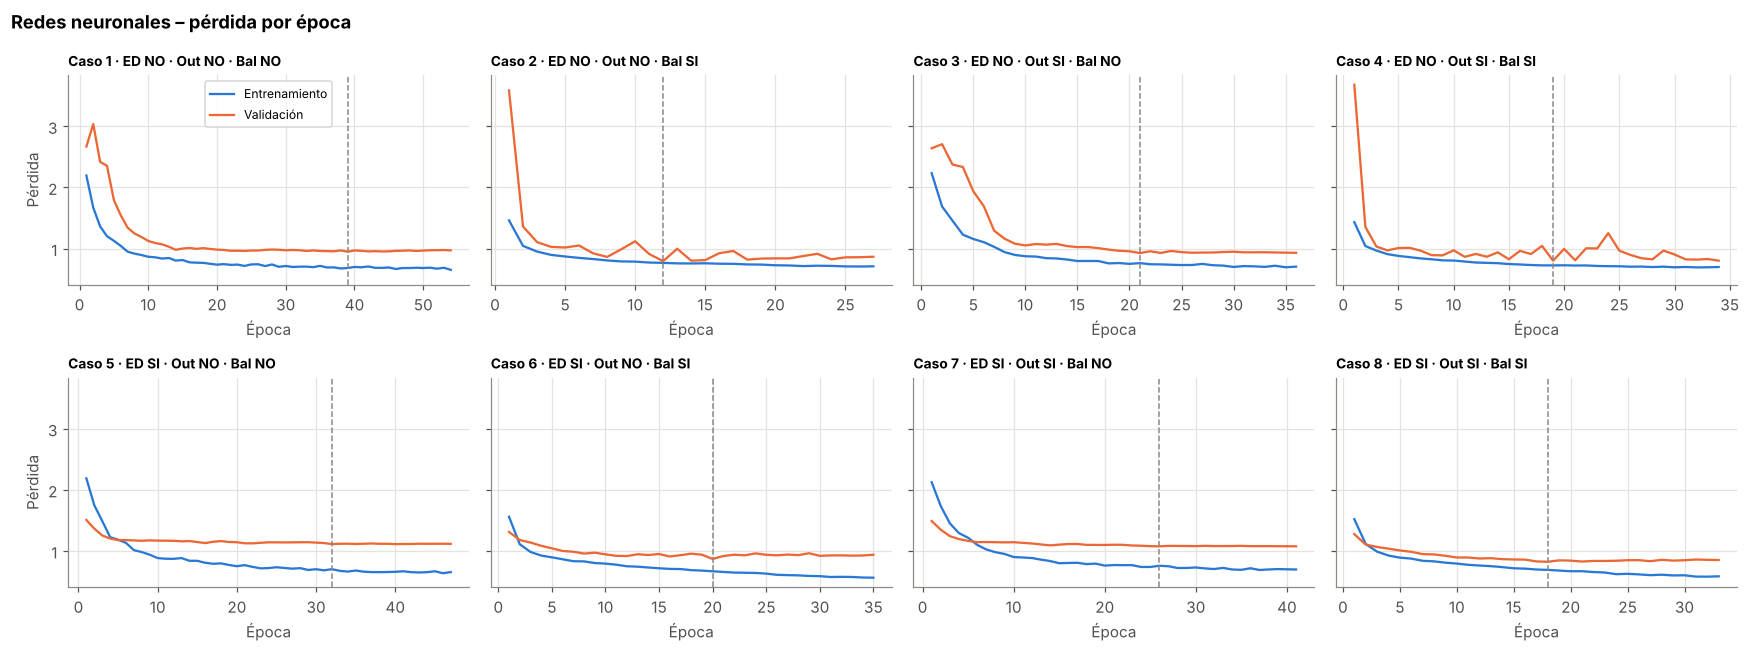

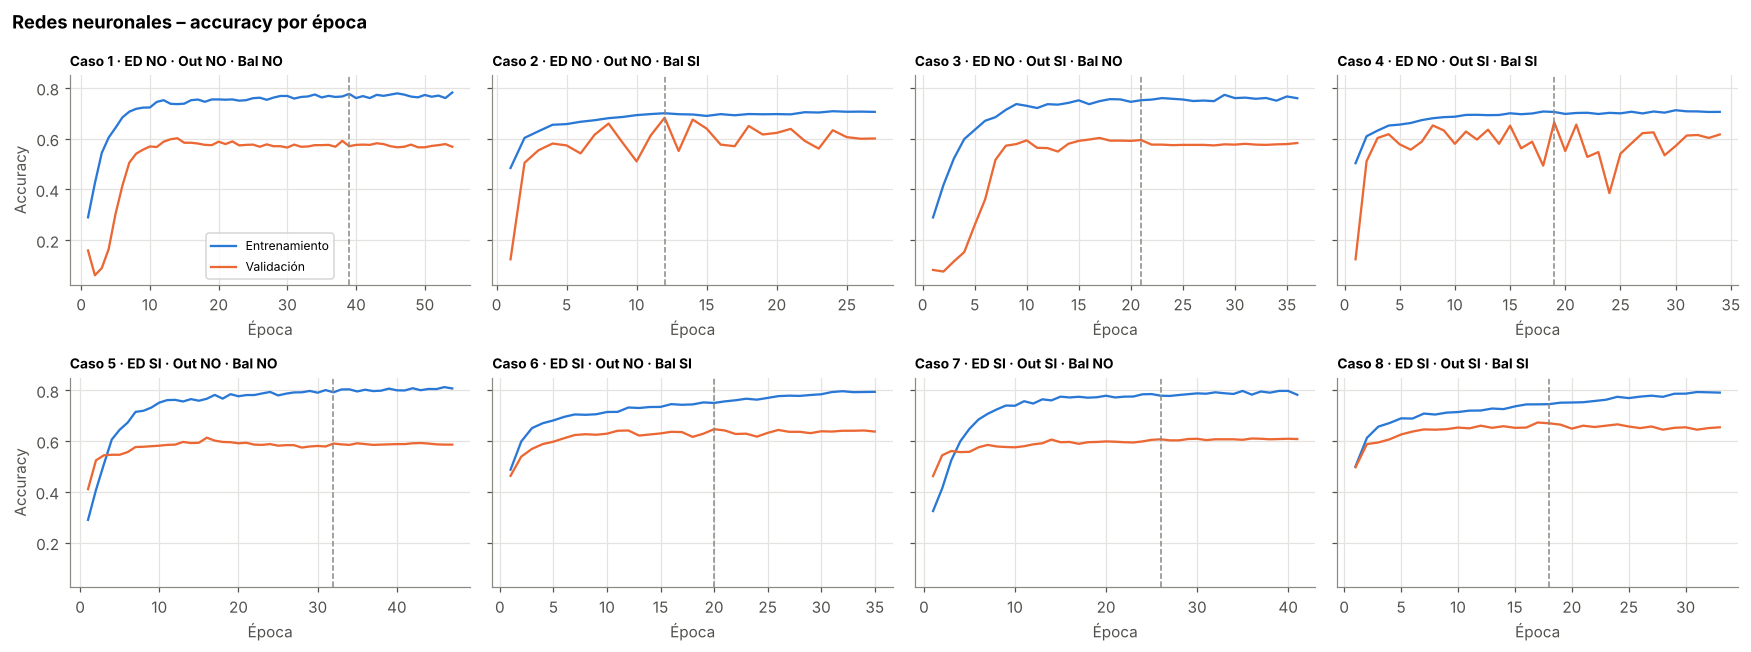

,Épocas entrenadas,Mejor época,Pérdida train,Pérdida val
Caso,,,,
1,54.0,39.0,0.6834,0.9502
2,27.0,12.0,0.7674,0.7961
3,36.0,21.0,0.7635,0.9279
4,34.0,19.0,0.7260,0.8033
5,47.0,32.0,0.7044,1.1136
6,35.0,20.0,0.6698,0.8709
7,41.0,26.0,0.7603,1.0777
8,33.0,18.0,0.6922,0.8251


In [39]:
def graficar_curvas_red(historias=HISTORIAS_RED, metrica="loss", etiqueta="Pérdida"):
    """Curvas de entrenamiento y validación de la red en los 8 casos para `metrica`
    ("loss" o "accuracy"). La línea punteada marca la época restaurada por EarlyStopping."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
    for ax, (k, h) in zip(axes.ravel(), historias.items()):
        epocas = np.arange(1, len(h[metrica]) + 1)
        ax.plot(epocas, h[metrica], color=COLORES_SERIES[0], label="Entrenamiento")
        ax.plot(epocas, h[f"val_{metrica}"], color=COLORES_SERIES[1], label="Validación")
        ax.axvline(int(np.argmin(h["val_loss"])) + 1, color="#8a8984", linestyle="--", linewidth=1)
        c = casos[k]
        ax.set_title(f"Caso {k} · ED {c['normalizacion'][-3:-1]} · Out {c['outliers']} · Bal {c['balanceo']}",
                     loc="left", fontsize=9)
        ax.set_xlabel("Época")
    for ax in axes[:, 0]:
        ax.set_ylabel(etiqueta)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Redes neuronales – {etiqueta.lower()} por época", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


graficar_curvas_red(metrica="loss", etiqueta="Pérdida")
graficar_curvas_red(metrica="accuracy", etiqueta="Accuracy")
display(pd.DataFrame({k: {"Épocas entrenadas": len(h["loss"]),
                          "Mejor época": int(np.argmin(h["val_loss"])) + 1,
                          "Pérdida train": round(h["loss"][int(np.argmin(h["val_loss"]))], 4),
                          "Pérdida val": round(min(h["val_loss"]), 4)}
                      for k, h in HISTORIAS_RED.items()}).T.rename_axis("Caso"))

- **EarlyStopping** detiene el entrenamiento entre las épocas 27 y 54 y restaura la mejor época (entre la 12 y la 39).
- **Sensibilidad a la escala:**
  - Sin escalar (casos 1–4), la pérdida de validación arranca en 2.6–3.7, frente a 1.3–1.5 con escalado.
  - El accuracy de validación oscila mucho más. Su desviación estándar desde la época 5 es de 0.042–0.068 sin escalar y de 0.009–0.012 con escalado; en el caso 4 recorre de 0.386 a 0.665.
  - Por eso, en esos casos el F1 final depende más de la época que restaura EarlyStopping.
- **Sobreajuste controlado:** en la mejor época, la mayor brecha entre la pérdida de validación y la de entrenamiento es 0.41 (caso 5); en los casos balanceados no pasa de 0.21.

#### 6.2.4 Por qué la red sin escalar no pierde F1: efecto de BatchNormalization
El F1 de prueba de los casos sin escalar no es menor que el de los escalados, a pesar de la inestabilidad. Para comprobar la causa, repetimos los casos 4 y 8 sin BatchNormalization.

In [40]:
def efecto_batch_norm(casos_exp=(4, 8), config=CONFIG_RED_FINAL):
    """Compara la red final con y sin BatchNormalization en los casos indicados:
    F1 macro de validación y desviación estándar del accuracy de validación desde la época 5
    (una medida de lo inestable que es el entrenamiento)."""
    filas = []
    for k in casos_exp:
        h_bn = HISTORIAS_RED[k]
        y_val_bn = predecir_con_probabilidades(MODELOS_RED[k], casos[k]["X_val"])[0]
        _, h_sin, f1_sin = entrenar_red(k, {**config, "batch_norm": False})
        for etiqueta, f1_val, h in (("Con BatchNorm", f1_score(casos[k]["y_val"], y_val_bn, average="macro"), h_bn),
                                    ("Sin BatchNorm", f1_sin, h_sin.history)):
            filas.append({"Caso": k, "ED": casos[k]["normalizacion"][-3:-1], "Red": etiqueta,
                          "F1 val": round(f1_val, 4),
                          "Desv. est. accuracy val (épocas ≥ 5)": round(np.std(h["val_accuracy"][4:]), 4)})
    return pd.DataFrame(filas).set_index(["Caso", "ED", "Red"])


display(efecto_batch_norm())

F1 val  Desv. est. accuracy val (épocas ≥ 5)
Caso ED Red                                                        
4    NO Con BatchNorm  0.6344                                0.0557
        Sin BatchNorm  0.5746                                0.0345
8    SI Con BatchNorm  0.6238                                0.0094
        Sin BatchNorm  0.6214                                0.0175

- Sin escalar (caso 4), quitar BatchNormalization baja el F1 de validación de 0.6344 a 0.5746. Con escalado (caso 8), apenas cambia (0.6238 frente a 0.6214).
- BatchNormalization reescala las activaciones de cada capa con estadísticas del lote. Eso compensa la diferencia de escala de las entradas, y por eso la red con BatchNormalization alcanza un F1 similar sin escalar.
- El escalado sigue siendo necesario para un entrenamiento estable: con BatchNormalization, la desviación estándar del accuracy de validación es 0.0557 sin escalar y 0.0094 con escalado.

#### 6.2.5 Evaluación de los 3 datos de prueba

In [41]:
# Evaluación de los 3 datos de prueba de demostración en los 8 casos
display(pd.concat([predecir_demo("Redes Neuronales", k, MODELOS_RED[k]) for k in casos]))

,Técnica,Real,Predicho,P(Nivel 1),P(Nivel 2),P(Nivel 3),P(Nivel 4)
3576,Redes Neuronales (caso 1),Nivel 1,Nivel 1,0.909,0.089,0.000,0.001
397,Redes Neuronales (caso 1),Nivel 3,Nivel 3,0.009,0.017,0.946,0.028
4354,Redes Neuronales (caso 1),Nivel 4,Nivel 3,0.004,0.013,0.902,0.082
3576,Redes Neuronales (caso 2),Nivel 1,Nivel 1,0.897,0.101,0.001,0.000
397,Redes Neuronales (caso 2),Nivel 3,Nivel 3,0.007,0.110,0.858,0.025
4354,Redes Neuronales (caso 2),Nivel 4,Nivel 3,0.008,0.092,0.836,0.064
3576,Redes Neuronales (caso 3),Nivel 1,Nivel 1,0.795,0.192,0.007,0.006
397,Redes Neuronales (caso 3),Nivel 3,Nivel 3,0.007,0.022,0.932,0.038
4354,Redes Neuronales (caso 3),Nivel 4,Nivel 3,0.008,0.020,0.872,0.100
3576,Redes Neuronales (caso 4),Nivel 1,Nivel 1,0.809,0.185,0.005,0.001


- Igual que el SVM, la red clasifica bien los registros de Nivel 1 y Nivel 3 en 7 de los 8 casos. En el caso 6 asigna Nivel 2 al registro de Nivel 1 (probabilidad 0.684).
- El registro de Nivel 4 se predice como Nivel 3 en los 8 casos, con una probabilidad de Nivel 4 de 0.100 como máximo. La red es más conservadora que el SVM con este registro.

#### 6.2.6 Caso 8: matriz de confusión y reporte por clase

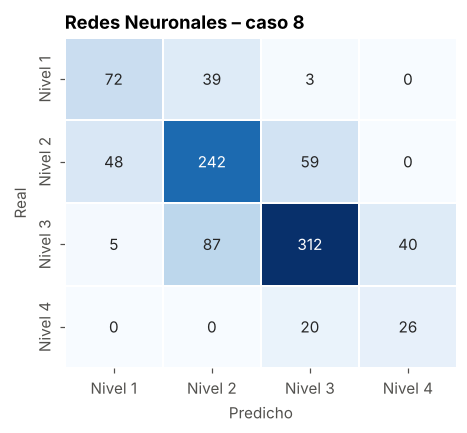

,precision,recall,f1-score,support
Nivel 1,0.5760,0.6316,0.6025,114.0000
Nivel 2,0.6576,0.6934,0.6750,349.0000
Nivel 3,0.7919,0.7027,0.7446,444.0000
Nivel 4,0.3939,0.5652,0.4643,46.0000
accuracy,0.6842,0.6842,0.6842,0.6842
macro avg,0.6049,0.6482,0.6216,953.0000
weighted avg,0.6977,0.6842,0.6886,953.0000


In [42]:
# Caso 8: matriz de confusión y reporte por clase
fig, ax = plt.subplots(figsize=(4.6, 3.9))
graficar_matriz_confusion("Redes Neuronales", 8, ax=ax)
plt.show()
display(reporte_por_clase("Redes Neuronales", 8))

- **Comparado con el SVM del caso 8**, la red tiene mayor accuracy (0.684 frente a 0.644) y mayor F1 macro (0.6216 frente a 0.5944).
- La mejora viene de Nivel 1 y Nivel 2: la precisión de Nivel 1 sube de 0.444 a 0.576 porque la red confunde menos estudiantes de Nivel 2 con Nivel 1 (48 frente a 85).
- **El costo está en Nivel 4:** el recall baja de 0.739 a 0.565 (26 de 46 detectados), y el recall de Nivel 1 baja de 0.667 a 0.632.
- Los errores también son casi todos entre niveles vecinos: solo 8 de los 301 errores saltan más de un nivel.
- Si se prioriza no dejar pasar estudiantes de Nivel 1, el SVM detecta 4 estudiantes más de los 114; la red los detecta con menos falsas alarmas.

### 6.3 Resumen del bloque 3

In [43]:
# ============================================================
# 6.3 Resumen del bloque 3
# ============================================================
def resumen_bloque3(algoritmos=("SVM", "Redes Neuronales")):
    """F1 macro de prueba por caso de los algoritmos del bloque y su promedio por factor
    de preprocesamiento (escalado, outliers y balanceo)."""
    tabla = tabla_figura1()[[(a, m) for a in algoritmos for m in METRICAS]]
    config = pd.DataFrame({k: {"ED": c["normalizacion"][-3:-1], "Outliers": c["outliers"],
                               "Balanceo": c["balanceo"]} for k, c in casos.items()}).T
    f1 = pd.concat([config, tabla.xs("F1", axis=1, level=1).astype(float)], axis=1)
    promedios = pd.concat({factor: f1.groupby(factor)[list(algoritmos)].mean()
                           for factor in ("ED", "Outliers", "Balanceo")}).round(4)
    return tabla, promedios


TABLA_BLOQUE3, PROMEDIOS_BLOQUE3 = resumen_bloque3()
display(TABLA_BLOQUE3)
print("F1 macro medio por factor:")
display(PROMEDIOS_BLOQUE3)

SVM                           Redes Neuronales                          
     Accuracy Precision  Recall      F1         Accuracy Precision  Recall      F1
Caso                                                                              
1      0.5897    0.5835  0.5792  0.5186           0.5866    0.6422  0.5843  0.5055
2      0.6432    0.5742   0.701  0.6052           0.6905    0.6397  0.6463  0.6385
3      0.5887    0.6009  0.5636   0.516           0.5908    0.6306  0.5558   0.498
4      0.6453    0.5666  0.6645  0.5949           0.6705    0.6491  0.6422  0.6378
5      0.5876     0.582  0.5718  0.5148            0.596    0.6098  0.5781  0.5269
6       0.639    0.5506  0.6131  0.5717            0.638    0.5534  0.6221  0.5739
7      0.5866    0.6005  0.5622  0.5135           0.6055    0.6341  0.5712  0.5339
8      0.6443     0.566  0.6654  0.5944           0.6842    0.6049  0.6482  0.6216

F1 macro medio por factor:


SVM  Redes Neuronales
         ED                          
ED       NO  0.5587            0.5700
         SI  0.5486            0.5641
Outliers NO  0.5526            0.5612
         SI  0.5547            0.5728
Balanceo NO  0.5157            0.5161
         SI  0.5916            0.6180

Con una sola semilla y 952 registros de validación, no interpretamos como mejoras las diferencias menores de 0.02 de F1.
- **El balanceo es el factor dominante.** El F1 medio sube de 0.5157 a 0.5916 en el SVM y de 0.5161 a 0.6180 en la red. En los casos desbalanceados, el accuracy (0.587–0.606) oculta el problema: el recall de Nivel 3 llega a 0.93 (SVM) y 0.94 (red) en el caso 7, mientras que el de Nivel 4 se queda en 0.50 (SVM) y 0.46 (red).
- **El escalado casi no cambia el F1 final** (SVM: 0.5587 sin escalar y 0.5486 con escalado; red: 0.5700 y 0.5641), porque la búsqueda del SVM elige configuraciones poco sensibles a la escala y BatchNormalization la compensa en la red. Con hiperparámetros fijos, sí importa: el RBF con gamma = 0.1 cae a 0.31–0.42 y la red sin BatchNormalization pierde 0.06. El escalado también es lo que hace estable el entrenamiento de la red.
- **Los outliers apenas afectan.** El F1 medio pasa de 0.5526 a 0.5547 en el SVM y de 0.5612 a 0.5728 en la red. Interpretamos que el 5 % de outliers queda absorbido por el margen suave del SVM (C ≤ 1) y por la regularización de la red.
- **Mejores resultados:** red en los casos 2 (0.6385) y 4 (0.6378), y SVM en el caso 2 (0.6052).

## 7. Evaluación comparativa (bloque 1)
*Se completa con los resultados registrados por los bloques 2 y 3: la tabla de la Figura 1 (`tabla_figura1()`), las 4 gráficas de F1, las curvas ROC/PR del caso 8 y el análisis general.*

# Módulo 2 – Aprendizaje no supervisado

## 8. K-Means y DBSCAN (bloque 4)
*Sección en desarrollo.*